In [ ]:
from google.colab import drive
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os, json, platform, warnings, time
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import shutil
from scipy.stats import randint, loguniform, uniform
from sklearn.model_selection import ParameterSampler
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import sklearn, platform

In [ ]:
train_path = kagglehub.dataset_download("pratyushakar/rossmann-store-sales", path="train.csv")
print("Path to train.csv:", train_path)

store_path = kagglehub.dataset_download("pratyushakar/rossmann-store-sales", path="store.csv")
print("Path to store.csv:", store_path)

Using Colab cache for faster access to the 'rossmann-store-sales' dataset.
Path to train.csv: /kaggle/input/rossmann-store-sales/train.csv
Using Colab cache for faster access to the 'rossmann-store-sales' dataset.
Path to store.csv: /kaggle/input/rossmann-store-sales/store.csv


In [ ]:
SEED = 42
np.random.seed(SEED)

TEST_DAYS  = 42
TEST_START = pd.Timestamp("2015-06-20")

H = 1

drive.mount("/content/drive")
RES_DIR = "/content/drive/MyDrive/rossmann"
OUT_DIR = os.path.join(RES_DIR, "processed")
FIG_DIR = os.path.join(RES_DIR, "figures")
TAB_DIR = os.path.join(RES_DIR, "tables")
for d in (OUT_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)
print("Результаты сохраняются в:", RES_DIR)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Результаты сохраняются в: /content/drive/MyDrive/rossmann


## 1. Data loading


In [ ]:
train = pd.read_csv(train_path, dtype={"StateHoliday": str}, parse_dates=["Date"])
store = pd.read_csv(store_path)

train = train.sort_values(["Store", "Date"]).reset_index(drop=True)

print("train:", train.shape, "| store:", store.shape)
display(train.head())
display(store.head())

train: (1017209, 9) | store: (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,2,2013-01-01,0,0,0,0,a,1
1,1,3,2013-01-02,5530,668,1,0,0,1
2,1,4,2013-01-03,4327,578,1,0,0,1
3,1,5,2013-01-04,4486,619,1,0,0,1
4,1,6,2013-01-05,4997,635,1,0,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


##2. Data audit (Section 3.2, Table 2)

### 2.1 Size, types, period, duplicates

In [ ]:
overview = pd.DataFrame({
    "file":         ["train", "store"],
    "observations": [len(train), len(store)],
    "variables":    [train.shape[1], store.shape[1]],
})
display(overview)

print("Period:", train["Date"].min().date(), "→", train["Date"].max().date())
print("Stores:", train["Store"].nunique(), "(store.csv:", store["Store"].nunique(), ")")
print("Duplicates (Store, Date):", train.duplicated(["Store", "Date"]).sum())
print("Complete string duplicates :", train.duplicated().sum())
print("Stores in the train that are not in the store.:", set(train.Store) - set(store.Store))
print()
print(train.dtypes)

,file,observations,variables
0,train,1017209,9
1,store,1115,10


Period: 2013-01-01 → 2015-07-31
Stores: 1115 (store.csv: 1115 )
Duplicates (Store, Date): 0
Complete string duplicates : 0
Stores in the train that are not in the store.: set()

Store                     int64
DayOfWeek                 int64
Date             datetime64[ns]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
dtype: object


### 2.2 Gaps

In [ ]:
miss_train = train.isna().sum().rename("train_missing")
miss_store = pd.DataFrame({"missing": store.isna().sum(),
                           "share_%": (store.isna().mean() * 100).round(1)})
print("train: пропусков нет" if miss_train.sum() == 0 else miss_train)
display(miss_store[miss_store.missing > 0])

print("\nPromo2=0  → Promo2Since*/PromoInterval пустые?  ",
      store.loc[store.Promo2 == 0, ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().all().all())
print("Promo2=1  → There are gaps in Promo2Since*?        ",
      store.loc[store.Promo2 == 1, ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().any().any())
print("CompetitionOpenSinceMonth NaN ⇔ ...Year NaN?      ",
      (store.CompetitionOpenSinceMonth.isna() == store.CompetitionOpenSinceYear.isna()).all())
print("Stores without CompetitionDistance:", store.loc[store.CompetitionDistance.isna(), "Store"].tolist())

train: пропусков нет


,missing,share_%
CompetitionDistance,3,0.3
CompetitionOpenSinceMonth,354,31.7
CompetitionOpenSinceYear,354,31.7
Promo2SinceWeek,544,48.8
Promo2SinceYear,544,48.8
PromoInterval,544,48.8



Promo2=0  → Promo2Since*/PromoInterval пустые?   True
Promo2=1  → There are gaps in Promo2Since*?         False
CompetitionOpenSinceMonth NaN ⇔ ...Year NaN?       True
Stores without CompetitionDistance: [291, 622, 879]


### 2.3 Logical consistency (Open / Sales / Customers)

In [ ]:
open_ = train["Open"] == 1
checks = {
    "Sales < 0":                        (train.Sales < 0).sum(),
    "Open=0 и Sales>0":                 ((~open_) & (train.Sales > 0)).sum(),
    "Open=1 и Sales=0":                 (open_ & (train.Sales == 0)).sum(),
    "Open=1 и Customers=0":             (open_ & (train.Customers == 0)).sum(),
    "Open=0 и Customers>0":             ((~open_) & (train.Customers > 0)).sum(),
    "Invalid values Promo":      (~train.Promo.isin([0, 1])).sum(),
    "Invalid values Open":       (~train.Open.isin([0, 1])).sum(),
    "DayOfWeek does not match with Date":    (train.Date.dt.dayofweek + 1 != train.DayOfWeek).sum(),
}
display(pd.Series(checks, name="n_rows").to_frame())
print("StateHoliday:", train.StateHoliday.value_counts().to_dict())
print("\nThe share of closed days: %.1f%%" % (100 * (~open_).mean()))

,n_rows
Sales < 0,0
Open=0 и Sales>0,0
Open=1 и Sales=0,54
Open=1 и Customers=0,52
Open=0 и Customers>0,0
Invalid values Promo,0
Invalid values Open,0
DayOfWeek does not match with Date,0


StateHoliday: {'0': 986159, 'a': 20260, 'b': 6690, 'c': 4100}

The share of closed days: 17.0%


### 2.3a Open days with zero turnover


In [ ]:
zero_open = train[open_ & (train.Sales == 0)]
print(len(zero_open), "lines; stores:", zero_open.Store.nunique())
display(zero_open.head(10))

54 lines; stores: 41


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
22463,25,3,2014-02-12,0,0,1,0,0,0
22464,25,4,2014-02-13,0,0,1,0,0,0
25491,28,2,2014-09-02,0,0,1,1,0,1
25492,28,3,2014-09-03,0,0,1,1,0,1
25493,28,4,2014-09-04,0,0,1,1,0,0
51642,57,2,2014-07-01,0,0,1,1,0,0
92755,102,6,2014-07-12,0,0,1,0,0,0
92767,102,4,2014-07-24,0,0,1,0,0,1
205598,227,4,2014-09-11,0,0,1,0,0,0
209529,232,4,2013-01-24,0,0,1,1,0,0


### 2.4 Missing dates

Lags and moving averages are calculated based on the calendar. If the store has no rows for certain dates, `shift(h)` by rows will give an incorrect lag (it will take the value from another day). Therefore, we check the completeness of the calendar.

In [ ]:
full_calendar = pd.date_range(train.Date.min(), train.Date.max(), freq="D")
rows_per_store = train.groupby("Store").size()

print("Days in the calendar:", len(full_calendar))
print(rows_per_store.value_counts().rename("n_stores").rename_axis("rows_per_store").to_frame())

gap_stores = rows_per_store[rows_per_store < len(full_calendar)].index
gap_info = []
for s in gap_stores:
    missing = full_calendar.difference(train.loc[train.Store == s, "Date"])
    gap_info.append((s, missing.min().date(), missing.max().date(), len(missing)))
gap_df = pd.DataFrame(gap_info, columns=["Store", "gap_start", "gap_end", "n_missing_days"])

print("\nStores with missing dates:", len(gap_df))
display(gap_df.groupby(["gap_start", "gap_end", "n_missing_days"]).size().rename("n_stores").reset_index())
print("The gaps affect the test period:", (pd.to_datetime(gap_df.gap_end) >= TEST_START).any())

Days in the calendar: 942
                n_stores
rows_per_store          
942                  934
758                  180
941                    1

Stores with missing dates: 181


,gap_start,gap_end,n_missing_days,n_stores
0,2013-01-01,2013-01-01,1,1
1,2014-07-01,2014-12-31,184,180


The gaps affect the test period: False


## 3. Chronological breakdown (only define the boundary, don’t train anything)

In [ ]:
train["is_test"] = train["Date"] >= TEST_START

split_summary = (train.assign(period=np.where(train.is_test, "test", "train"))
                      .groupby("period")
                      .agg(start=("Date", "min"), end=("Date", "max"),
                           days=("Date", "nunique"), rows=("Date", "size"),
                           open_rows=("Open", "sum")))
display(split_summary)
assert split_summary.loc["test", "days"] == TEST_DAYS, "The test window must be exactly 42 days."

,start,end,days,rows,open_rows
period,,,,,
test,2015-06-20,2015-07-31,42,46830,40282
train,2013-01-01,2015-06-19,900,970379,804110


**Next, we perform EDA only during the training period and only on open days**, just as the models will be trained.

The test period is not involved in the exploration (except for one overview image with a split).

In [ ]:
tr = train[~train.is_test]
eda = (tr[tr.Open == 1].drop(columns="is_test")
         .merge(store, on="Store", how="left"))
print("EDA sample:", eda.shape)

EDA sample: (804110, 18)


## 4. EDA
### 4.1 Target variable

,Sales
count,804110.0
mean,6954.4
std,3106.7
min,0.0
1%,2182.0
5%,3169.0
25%,4856.0
50%,6368.0
75%,8360.0
95%,12671.0


Asymmetry: 1.59 | Excess: 4.84


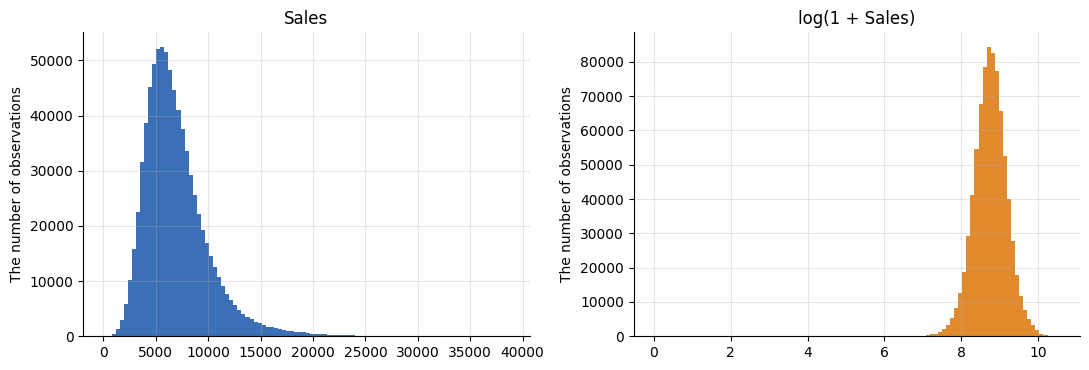

In [ ]:
desc = eda["Sales"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1)
display(desc.to_frame("Sales"))
print("Asymmetry: %.2f | Excess: %.2f" % (eda.Sales.skew(), eda.Sales.kurt()))
desc.to_csv(f"{TAB_DIR}/eda_sales_describe.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(eda.Sales, bins=100, color="#3b6fb6"); ax[0].set_title("Sales")
ax[1].hist(np.log1p(eda.Sales), bins=100, color="#e08a2c"); ax[1].set_title("log(1 + Sales)")
for a in ax: a.set_ylabel("The number of observations")
savefig("fig_eda_sales_distribution")

### 4.2 Dynamics over time + train/test boundary

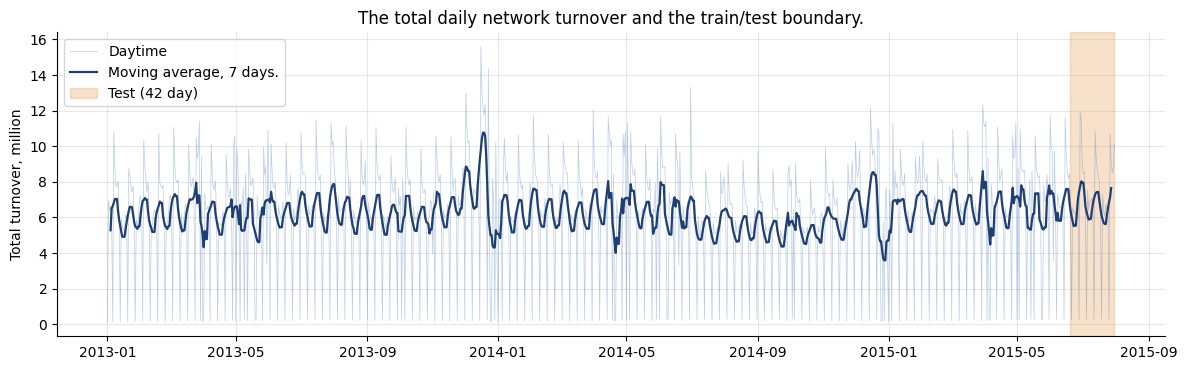

In [ ]:
daily = train[train.Open == 1].groupby("Date")["Sales"].sum() / 1e6

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily.values, lw=.5, color="#3b6fb6", alpha=.35, label="Daytime")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), lw=1.6, color="#1f3f73", label="Moving average, 7 days.")
ax.axvspan(TEST_START, train.Date.max(), color="#e08a2c", alpha=.25, label="Test (42 day)")
ax.set_ylabel("Total turnover, million"); ax.set_title("The total daily network turnover and the train/test boundary.")
ax.legend()
savefig("fig_split_timeline")

### 4.3 Calendar effects (training period, open days)

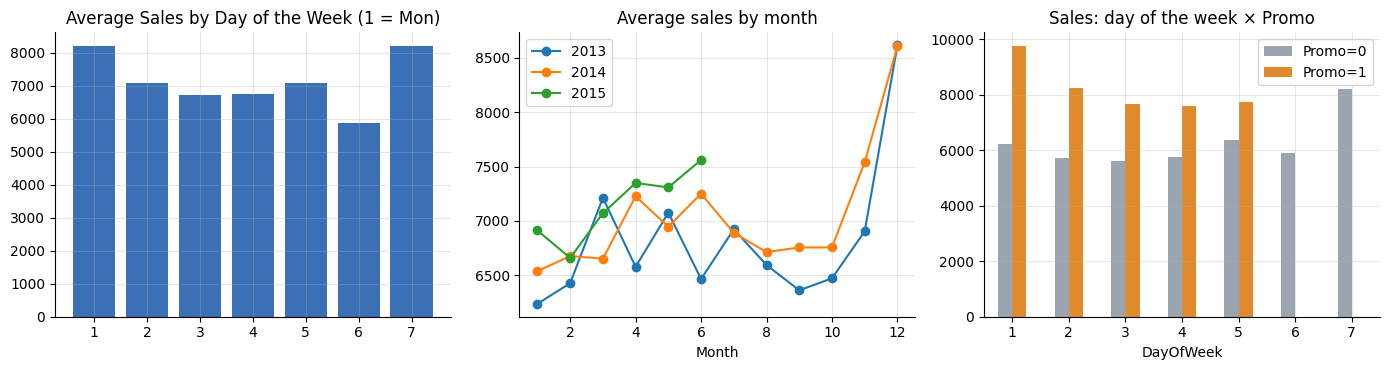

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

dow = eda.groupby("DayOfWeek")["Sales"].mean()
ax[0].bar(dow.index, dow.values, color="#3b6fb6"); ax[0].set_title("Average Sales by Day of the Week (1 = Mon)")

for y, g in eda.groupby(eda.Date.dt.year):
    m = g.groupby(g.Date.dt.month)["Sales"].mean()
    ax[1].plot(m.index, m.values, marker="o", label=str(y))
ax[1].set_title("Average sales by month"); ax[1].set_xlabel("Month"); ax[1].legend()

wk = eda.groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack()
wk.plot(kind="bar", ax=ax[2], color=["#9aa5b1", "#e08a2c"]); ax[2].set_title("Sales: day of the week × Promo")
ax[2].legend(["Promo=0", "Promo=1"]); ax[2].tick_params(axis="x", rotation=0)
savefig("fig_eda_calendar")

### 4.4 Promotions, holidays, store features

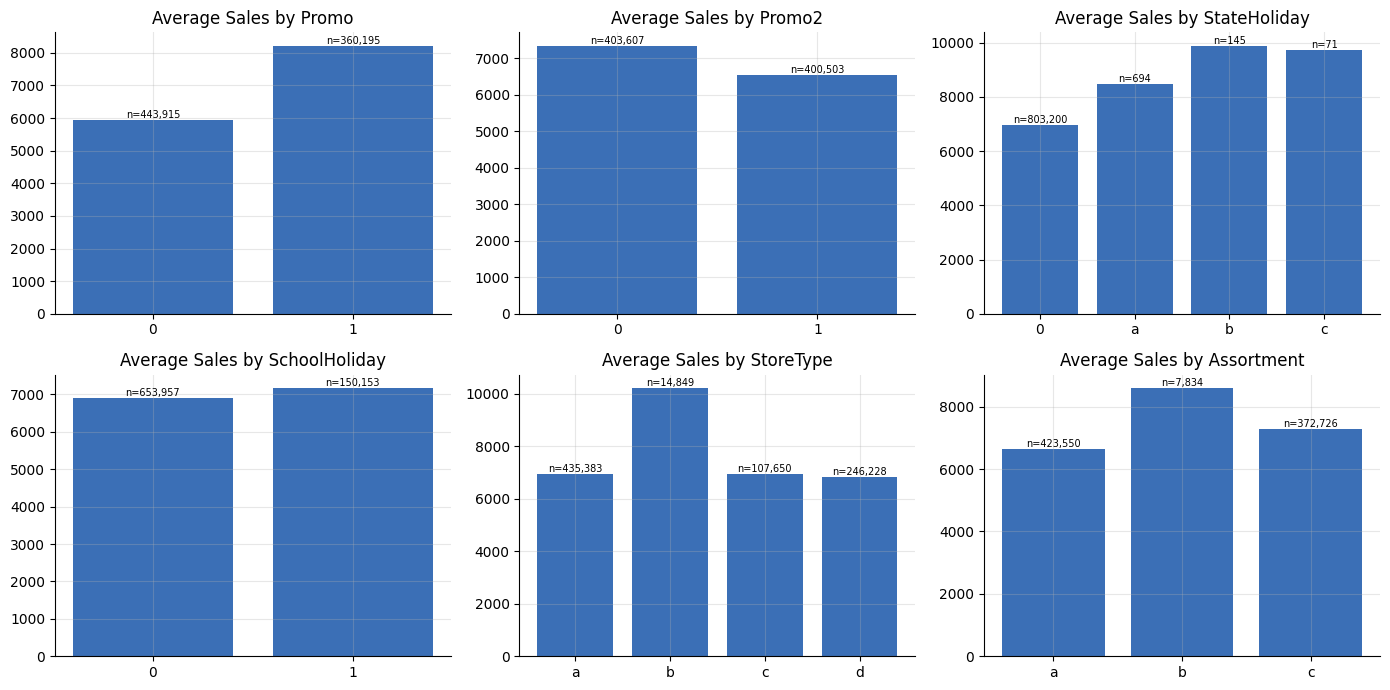

count     mean  median     std
Promo         0  443915   5930.7  5456.0  2637.7
              1  360195   8216.0  7635.0  3176.2
Promo2        0  403607   7349.4  6683.0  3396.8
              1  400503   6556.3  6073.0  2726.6
StateHoliday  0  803200   6952.3  6367.0  3101.1
              a     694   8487.5  7556.0  5708.6
              b     145   9887.9  8423.0  7551.8
              c      71   9743.7  8397.0  5980.9
SchoolHoliday 0  653957   6906.1  6336.0  3087.8
              1  150153   7164.4  6517.0  3179.0
StoreType     a  435383   6927.6  6288.0  3279.2
              b   14849  10203.7  9107.0  5174.1
              c  107650   6934.8  6409.0  2907.7
              d  246228   6814.2  6389.0  2556.7
Assortment    a  423550   6626.8  6088.0  2976.6
              b    7834   8588.7  8014.5  3822.1
              c  372726   7292.3  6667.0  3186.5

In [ ]:
groups = ["Promo", "Promo2", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, col in zip(axes.ravel(), groups):
    m = eda.groupby(col)["Sales"].agg(["mean", "count"])
    a.bar(m.index.astype(str), m["mean"], color="#3b6fb6")
    a.set_title(f"Average Sales by {col}")
    for i, (v, n) in enumerate(zip(m["mean"], m["count"])):
        a.text(i, v, f"n={n:,}", ha="center", va="bottom", fontsize=7)
savefig("fig_eda_categorical")

summary_cat = pd.concat({c: eda.groupby(c)["Sales"].agg(["count", "mean", "median", "std"]).round(1)
                         for c in groups})
summary_cat.to_csv(f"{TAB_DIR}/eda_sales_by_category.csv")
display(summary_cat)

### 4.5 Competitors

/tmp/ipykernel_23968/472506460.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  m = cd.groupby("dist_bin")["Sales"].mean()


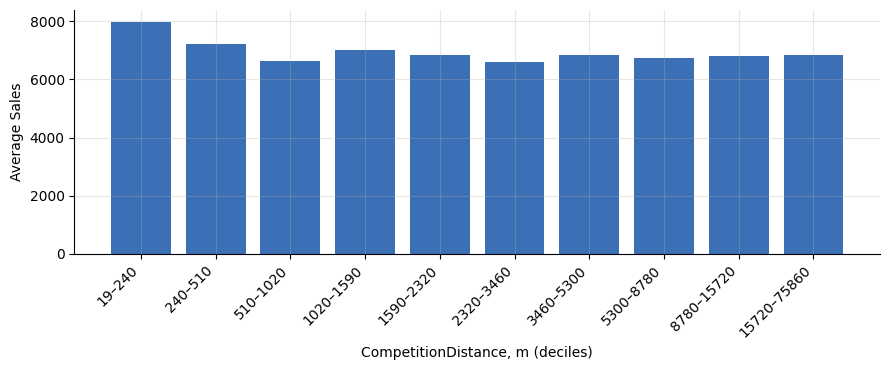

In [ ]:
cd = eda.dropna(subset=["CompetitionDistance"]).copy()
cd["dist_bin"] = pd.qcut(cd.CompetitionDistance, 10, duplicates="drop")
m = cd.groupby("dist_bin")["Sales"].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(m)), m.values, color="#3b6fb6")
ax.set_xticks(range(len(m))); ax.set_xticklabels([f"{int(i.left)}–{int(i.right)}" for i in m.index], rotation=45, ha="right")
ax.set_xlabel("CompetitionDistance, m (deciles)"); ax.set_ylabel("Average Sales")
savefig("fig_eda_competition")

### 4.6 Sales vs Customers — why the Customers of the current day cannot be used

The correlation is very high, but the number of customers on the forecast day is unknown in advance (Sections 1 and 3.2 of the article).

Only its **lags** will be included in the model.

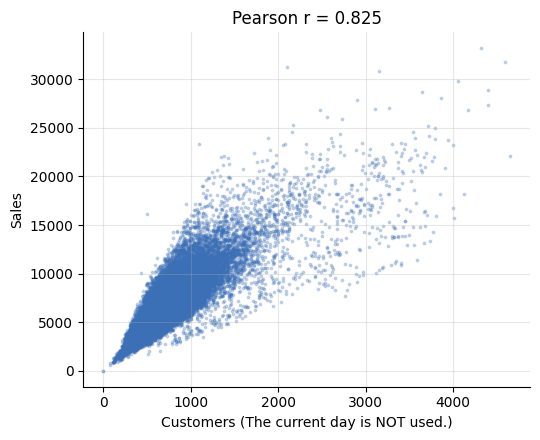

In [ ]:
samp = eda.sample(30000, random_state=SEED)
r = eda[["Sales", "Customers"]].corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(samp.Customers, samp.Sales, s=3, alpha=.25, color="#3b6fb6")
ax.set_xlabel("Customers (The current day is NOT used.)"); ax.set_ylabel("Sales")
ax.set_title(f"Pearson r = {r:.3f}")
savefig("fig_eda_sales_vs_customers")

### 4.7 The spread between stores

,mean,std,count,cv
count,1115.0,1115.0,1115.0,1115.0
mean,6932.1,1847.0,721.2,0.3
std,2385.1,623.4,63.4,0.1
min,2707.1,579.4,556.0,0.1
25%,5318.3,1410.6,740.5,0.2
50%,6598.8,1765.5,743.0,0.3
75%,7968.2,2154.9,746.0,0.3
max,21803.5,4905.7,900.0,0.6


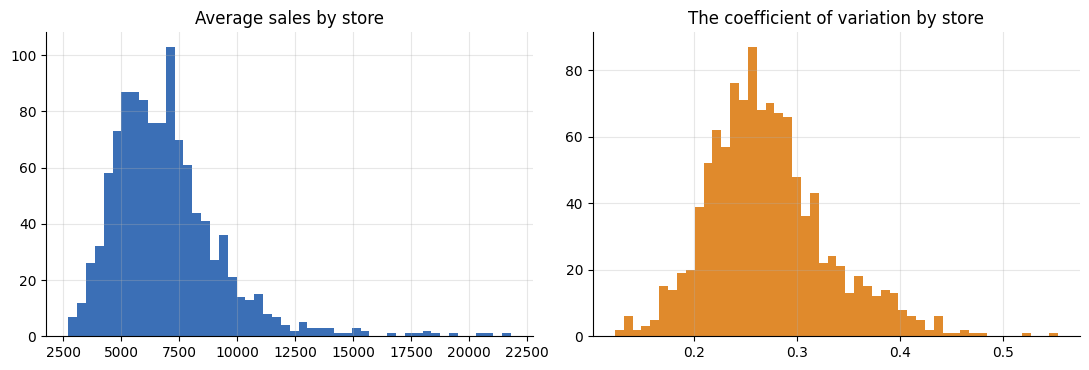

In [ ]:
per_store = eda.groupby("Store")["Sales"].agg(["mean", "std", "count"])
per_store["cv"] = per_store["std"] / per_store["mean"]
display(per_store.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(per_store["mean"], bins=50, color="#3b6fb6"); ax[0].set_title("Average sales by store")
ax[1].hist(per_store["cv"], bins=50, color="#e08a2c");   ax[1].set_title("The coefficient of variation by store")
savefig("fig_eda_store_heterogeneity")

## 5. Conclusions of Stage 1 (for yourself / for Section 4)

In [ ]:
print(f"""
- Lines in train: {len(train):,}; stores: {train.Store.nunique()}; period {train.Date.min().date()} – {train.Date.max().date()}.
- Closed days: {(train.Open==0).mean()*100:.1f}% (Sales=0) — exclude from training and assessment.
- Open days с Sales=0: {len(zero_open)} — We keep it; we calculate MAPE when Sales > 0.
- Stores with a skip of 184 dates (2014-07-01..2014-12-31): {(gap_df.n_missing_days == 184).sum()} (+{(gap_df.n_missing_days < 184).sum()} with the skip of 2013-01-01) → calculate lags based on the full calendar (reindex), not based on shift rows.
- Test: {split_summary.loc['test','start'].date()} – {split_summary.loc['test','end'].date()}, {int(split_summary.loc['test','rows']):,} rows (of which are open {int(split_summary.loc['test','open_rows']):,}).
- Training dataset for EDA / models: {len(eda):,} open strings.
""")


- Lines in train: 1,017,209; stores: 1115; period 2013-01-01 – 2015-07-31.
- Closed days: 17.0% (Sales=0) — exclude from training and assessment.
- Open days с Sales=0: 54 — We keep it; we calculate MAPE when Sales > 0.
- Stores with a skip of 184 dates (2014-07-01..2014-12-31): 180 (+1 with the skip of 2013-01-01) → calculate lags based on the full calendar (reindex), not based on shift rows.
- Test: 2015-06-20 – 2015-07-31, 46,830 rows (of which are open 40,282).
- Training dataset for EDA / models: 804,110 open strings.



In [ ]:
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)
print(train.shape, store.shape)

(1017209, 10) (1115, 10)


## 2. Sales history indicators (Historical sales group)

Calculate on the **full calendar** of each store (matrix “date × store”): days that are not in `train.csv`

(for 180 stores — 01.07–31.12.2014) remain gaps and are not “shifted”.

* Sales_lag{k} — turnover k days ago (closed day = 0, this is the actual value);
* Sales_rmean{w} — average turnover over the last w calendar days, only on open days;
* Customers_lag{k}, Customers_rmean{w} — the same for the number of customers;
* all windows end on day t−H.

In [ ]:
LAG_OFFSETS   = (0, 6, 13, 27)
SALES_WINDOWS = (7, 14, 28)
CUST_LAGS     = (0, 6)
CUST_WINDOWS  = (7, 28)

def build_history(df, h=H):
    """df: lines of the train file (Store, Date, Sales, Customers, Open).
    Returns a DataFrame with an index (Store, Date): features that use data no later than day t-h."""
    S = df.pivot(index="Date", columns="Store", values="Sales")
    C = df.pivot(index="Date", columns="Store", values="Customers")
    O = df.pivot(index="Date", columns="Store", values="Open")
    cal = pd.date_range(S.index.min(), S.index.max(), freq="D")
    S, C, O = (x.reindex(cal) for x in (S, C, O))
    S_open, C_open = S.where(O == 1), C.where(O == 1)

    out = {}
    for off in LAG_OFFSETS:
        out[f"Sales_lag{h+off}"] = S.shift(h + off)
    for w in SALES_WINDOWS:
        out[f"Sales_rmean{w}"] = S_open.rolling(w, min_periods=1).mean().shift(h)
    for off in CUST_LAGS:
        out[f"Customers_lag{h+off}"] = C.shift(h + off)
    for w in CUST_WINDOWS:
        out[f"Customers_rmean{w}"] = C_open.rolling(w, min_periods=1).mean().shift(h)

    hist = pd.DataFrame({k: v.unstack() for k, v in out.items()})
    hist.index.names = ["Store", "Date"]
    return hist

hist = build_history(train)
HIST_COLS = list(hist.columns)
print(hist.shape); print(HIST_COLS)

(1050330, 11)
['Sales_lag1', 'Sales_lag7', 'Sales_lag14', 'Sales_lag28', 'Sales_rmean7', 'Sales_rmean14', 'Sales_rmean28', 'Customers_lag1', 'Customers_lag7', 'Customers_rmean7', 'Customers_rmean28']


### 2.1 Leak test

We spoil all `Sales`/`Customers` starting from date D and recalculate the attributes. Signs on dates **≤ D** should not

change not a single penny (the attribute on date D uses only data up to D−1).

In [ ]:
def leakage_test(D=TEST_START):
    bad = train.copy()
    m = bad["Date"] >= D
    bad.loc[m, ["Sales", "Customers"]] = 9_999_999
    h2 = build_history(bad)
    dates = hist.index.get_level_values("Date")
    a, b = hist[dates <= D], h2[h2.index.get_level_values("Date") <= D]
    same = a.equals(b) or np.allclose(a.values, b.values, equal_nan=True)
    changed_after = not np.allclose(hist[dates > D].values, h2[h2.index.get_level_values("Date") > D].values, equal_nan=True)
    return same, changed_after

same, changed_after = leakage_test()
print("Signs on dates ≤ D are independent of the future:", same)
print("(control) signs after D react to data corruption:", changed_after)
assert same and changed_after, "LEAK or error in the test!"

Signs on dates ≤ D are independent of the future: True
(control) signs after D react to data corruption: True


## 3. Modeling strings and calendar features

Only open days (`Open = 1`). Open days with `Sales = 0` (54 pcs.) remain.

In [ ]:
rows = train[train["Open"] == 1].copy()
rows = rows.join(hist, on=["Store", "Date"])

rows["Year"]  = rows["Date"].dt.year
rows["Month"] = rows["Date"].dt.month
rows["Day"]   = rows["Date"].dt.day

rows["is_test"] = rows["Date"] >= TEST_START
print("train-lines:", (~rows.is_test).sum(), "| test-lines:", rows.is_test.sum())

train-lines: 804110 | test-lines: 40282


## 4. Promo and store attributes (derived, variant A)

* `Promo2Active` - participation in Promo2 has already begun by the date (according to Promo2SinceYear/Week, ISO week).
* `Promo2RoundMonth` - the month is included in the store’s PromoInterval.
* `CompetitionOpenMonths` - months since the competitor’s opening (before opening = 0; the upper threshold is from train, see below).
* `CompetitionOpenUnknown` - the competition opening date is unknown (in which case CompetitionOpenMonths = 0).

In [ ]:
MONTHS = {"Jan":1,"Feb":2,"Mar":3,"Apr":4,"May":5,"Jun":6,"Jul":7,"Aug":8,"Sep":9,"Sept":9,"Oct":10,"Nov":11,"Dec":12}
st = store.copy()

has_p2 = st["Promo2"] == 1
yr = st.loc[has_p2, "Promo2SinceYear"].astype(int).astype(str)
wk = st.loc[has_p2, "Promo2SinceWeek"].astype(int).astype(str).str.zfill(2)
st["Promo2Start"] = pd.NaT
st.loc[has_p2, "Promo2Start"] = pd.to_datetime(yr + "-W" + wk + "-1", format="%G-W%V-%u", errors="coerce")
assert st.loc[has_p2, "Promo2Start"].notna().all(), "Failed to parse the start. Promo2"
st["Promo2Start"] = pd.to_datetime(st["Promo2Start"])

st["PromoInterval"] = st["PromoInterval"].fillna("none")
INTERVALS = [iv for iv in sorted(st.PromoInterval.unique()) if iv != "none"]
print("PromoInterval:", INTERVALS)

keep = ["Store", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth",
        "CompetitionOpenSinceYear", "Promo2", "Promo2Start", "PromoInterval"]
rows = rows.merge(st[keep], on="Store", how="left")

rows["Promo2Active"] = ((rows["Promo2"] == 1) & (rows["Date"] >= rows["Promo2Start"])).astype(int)

rows["Promo2RoundMonth"] = 0
for iv in INTERVALS:
    months = [MONTHS[m] for m in iv.split(",")]
    rows.loc[(rows["PromoInterval"] == iv) & rows["Month"].isin(months), "Promo2RoundMonth"] = 1

unk = rows["CompetitionOpenSinceYear"].isna() | rows["CompetitionOpenSinceMonth"].isna()
rows["CompetitionOpenUnknown"] = unk.astype(int)
months_raw = ((rows["Year"] * 12 + rows["Month"]) -
              (rows["CompetitionOpenSinceYear"] * 12 + rows["CompetitionOpenSinceMonth"]))
rows["CompetitionOpenMonths_raw"] = months_raw.clip(lower=0).where(~unk, 0)

print("Promo2Active, share 1 (open days):", rows.Promo2Active.mean().round(3),
      "| Promo2=1:", rows.Promo2.mean().round(3))

PromoInterval: ['Feb,May,Aug,Nov', 'Jan,Apr,Jul,Oct', 'Mar,Jun,Sept,Dec']
Promo2Active, share 1 (open days): 0.431 | Promo2=1: 0.499


## 5. Parameters evaluated ONLY during the training period

Median `CompetitionDistance`, threshold `CompetitionOpenMonths` (99th percentile — outlier protection: store 815 with the competitor’s opening year 1900), medians for filling in missing values in historical features.

In [ ]:
trn = rows[~rows.is_test]

params = {
    "H": H, "test_start": str(TEST_START.date()),
    "CompetitionDistance_median": float(trn["CompetitionDistance"].median()),
    "CompetitionOpenMonths_cap":  float(trn["CompetitionOpenMonths_raw"].quantile(0.99)),
    "hist_medians": {c: float(trn[c].median()) for c in HIST_COLS},
}
print(json.dumps({k: v for k, v in params.items() if k != "hist_medians"}, indent=1))
print("Max. CompetitionOpenMonths_raw up to the threshold:", rows.CompetitionOpenMonths_raw.max())

rows["CompetitionDistance"]   = rows["CompetitionDistance"].fillna(params["CompetitionDistance_median"])
rows["CompetitionOpenMonths"] = rows["CompetitionOpenMonths_raw"].clip(upper=params["CompetitionOpenMonths_cap"])

rows["HistMissing"] = rows[HIST_COLS].isna().any(axis=1).astype(int)
for c in HIST_COLS:
    rows[c] = rows[c].fillna(params["hist_medians"][c])
print("The proportion of lines with filled-in gaps in the history (train): %.2f%%, (test): %.2f%%" %
      (100 * rows.loc[~rows.is_test, "HistMissing"].mean(), 100 * rows.loc[rows.is_test, "HistMissing"].mean()))

{
 "H": 1,
 "test_start": "2015-06-20",
 "CompetitionDistance_median": 2320.0,
 "CompetitionOpenMonths_cap": 195.0
}
Max. CompetitionOpenMonths_raw up to the threshold: 1386.0
The proportion of lines with filled-in gaps in the history (train): 3.68%, (test): 0.00%


## 6. One-hot (the same for all models)

Fix the levels in advance. Discard the first level (reference): `StoreType=a`, `Assortment=a`, `StateHoliday=0`, `PromoInterval=none`.

In [ ]:
CATS = {
    "StoreType":     ["a", "b", "c", "d"],
    "Assortment":    ["a", "b", "c"],
    "StateHoliday":  ["0", "a", "b", "c"],
    "PromoInterval": ["none"] + INTERVALS,
}
for col, levels in CATS.items():
    assert set(rows[col].unique()) <= set(levels), f"unknown level in {col}"
    rows[col] = pd.Categorical(rows[col], categories=levels)

dummies = pd.get_dummies(rows[list(CATS)], drop_first=True, dtype=float)
dummies.columns = [c.replace(",", "-") for c in dummies.columns]
rows = pd.concat([rows.drop(columns=list(CATS)), dummies], axis=1)

## 7. Groups of features (Table 3) for ablation

In [ ]:
GROUPS = {
    "Temporal":      ["Year", "Month", "Day", "DayOfWeek"],
    "Historical":    HIST_COLS + ["HistMissing"],
    "Promo_Holiday": ["Promo", "Promo2", "Promo2Active", "Promo2RoundMonth", "SchoolHoliday"]
                     + [c for c in dummies.columns if c.startswith(("StateHoliday_", "PromoInterval_"))],
    "Store":         [c for c in dummies.columns if c.startswith(("StoreType_", "Assortment_"))]
                     + ["CompetitionDistance", "CompetitionOpenMonths", "CompetitionOpenUnknown"],
}
FEATURES = [c for g in GROUPS.values() for c in g]

assert len(FEATURES) == len(set(FEATURES)), "дубликаты признаков"
assert not {"Sales", "Customers", "Open", "Store", "Date"} & set(FEATURES), "The prohibited column in the features!"
assert rows[FEATURES].isna().sum().sum() == 0, "остались NaN"

print("Total number of features:", len(FEATURES))
for g, cols in GROUPS.items():
    print(f"\n[{g}] ({len(cols)})\n  ", ", ".join(cols))

Total number of features: 35

[Temporal] (4)
   Year, Month, Day, DayOfWeek

[Historical] (12)
   Sales_lag1, Sales_lag7, Sales_lag14, Sales_lag28, Sales_rmean7, Sales_rmean14, Sales_rmean28, Customers_lag1, Customers_lag7, Customers_rmean7, Customers_rmean28, HistMissing

[Promo_Holiday] (11)
   Promo, Promo2, Promo2Active, Promo2RoundMonth, SchoolHoliday, StateHoliday_a, StateHoliday_b, StateHoliday_c, PromoInterval_Feb-May-Aug-Nov, PromoInterval_Jan-Apr-Jul-Oct, PromoInterval_Mar-Jun-Sept-Dec

[Store] (8)
   StoreType_b, StoreType_c, StoreType_d, Assortment_b, Assortment_c, CompetitionDistance, CompetitionOpenMonths, CompetitionOpenUnknown


## 8. Breaking and sanity-check

In [ ]:
cols_keep = ["Store", "Date", "Sales"] + FEATURES
train_df = rows.loc[~rows.is_test, cols_keep].reset_index(drop=True)
test_df  = rows.loc[ rows.is_test, cols_keep].reset_index(drop=True)
train_df[FEATURES] = train_df[FEATURES].astype("float32")
test_df[FEATURES]  = test_df[FEATURES].astype("float32")

print("train:", train_df.shape, train_df.Date.min().date(), "→", train_df.Date.max().date())
print("test :", test_df.shape,  test_df.Date.min().date(),  "→", test_df.Date.max().date())
assert train_df.Date.max() < test_df.Date.min()

sh = [c for c in FEATURES if c.startswith("StateHoliday_")]
print("\nStateHoliday in the test (dummy amount):", test_df[sh].sum().to_dict(), "| в train:", train_df[sh].sum().astype(int).to_dict())

corr = train_df[HIST_COLS + ["Sales"]].corr()["Sales"].drop("Sales").sort_values(ascending=False)
display(corr.round(3).to_frame("corr_with_Sales"))

def mae(a, b): return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
ok = test_df["HistMissing"] == 0
naive = pd.DataFrame({
    "MAE":  {c: mae(test_df.loc[ok, "Sales"], test_df.loc[ok, c]) for c in ["Sales_lag7", "Sales_rmean7", "Sales_rmean28"]},
    "RMSE": {c: rmse(test_df.loc[ok, "Sales"], test_df.loc[ok, c]) for c in ["Sales_lag7", "Sales_rmean7", "Sales_rmean28"]},
}).round(1)
display(naive)
print("For reference: average Sales in the test = %.0f" % test_df.Sales.mean())

train: (804110, 38) 2013-01-01 → 2015-06-19
test : (40282, 38) 2015-06-20 → 2015-07-31

StateHoliday in the test (dummy amount): {'StateHoliday_a': 0.0, 'StateHoliday_b': 0.0, 'StateHoliday_c': 0.0} | в train: {'StateHoliday_a': 694, 'StateHoliday_b': 145, 'StateHoliday_c': 71}


,corr_with_Sales
Sales_rmean28,0.783
Sales_rmean14,0.780
Sales_rmean7,0.754
Sales_lag14,0.743
Sales_lag28,0.705
Customers_rmean28,0.657
Customers_rmean7,0.655
Customers_lag7,0.573
Sales_lag7,0.553
Sales_lag1,0.390


,MAE,RMSE
Sales_lag7,2191.2,2828.1
Sales_rmean7,1525.7,2126.7
Sales_rmean28,1443.8,1885.4


For reference: average Sales in the test = 6979


## 9. Preservation for the subsequent stages

In [ ]:
def save_df(df, name):
    try:
        df.to_parquet(os.path.join(OUT_DIR, name + ".parquet"), index=False); return name + ".parquet"
    except ImportError:                                  # pyarrow нет (локальный тест)
        df.to_pickle(os.path.join(OUT_DIR, name + ".pkl")); return name + ".pkl"

print(save_df(train_df, "train_processed"), save_df(test_df, "test_processed"))
with open(os.path.join(OUT_DIR, "feature_groups.json"), "w") as f: json.dump(GROUPS, f, indent=1)
with open(os.path.join(OUT_DIR, "preproc_params.json"), "w") as f: json.dump(params, f, indent=1)
print("Saved in", OUT_DIR, "→", sorted(os.listdir(OUT_DIR)))

train_processed.parquet test_processed.parquet
Saved in /content/drive/MyDrive/rossmann/processed → ['feature_groups.json', 'preproc_params.json', 'test_processed.parquet', 'train_processed.parquet']


# Stage 3. Metrics, baseline benchmarks, linear regression, CV scheme

Input: files from Stage 2 (`processed/`). Here:

1. metric functions (MAE, RMSE, MAPE when Sales>0, R²)
2. naive benchmarks (not the article’s models, but a starting point)
3. **linear regression** (basic model): training on train, evaluation on test
4. cross‑validation scheme with an expanding window (4 folds × 42 days) — we use the same one for RF and XGBoost
5. graphs and saving predictions for comparing models in subsequent stages.

## 0. Settings and loading

In [ ]:
def load_df(name):
    p = os.path.join(OUT_DIR, name + ".parquet")
    return pd.read_parquet(p) if os.path.exists(p) else pd.read_pickle(os.path.join(OUT_DIR, name + ".pkl"))

train_df, test_df = load_df("train_processed"), load_df("test_processed")
GROUPS = json.load(open(os.path.join(OUT_DIR, "feature_groups.json")))
PARAMS = json.load(open(os.path.join(OUT_DIR, "preproc_params.json")))
FEATURES = [c for g in GROUPS.values() for c in g]
TEST_START = pd.Timestamp(PARAMS["test_start"])

X_tr, y_tr = train_df[FEATURES], train_df["Sales"].astype(float)
X_te, y_te = test_df[FEATURES],  test_df["Sales"].astype(float)
print("train", X_tr.shape, "| test", X_te.shape, "| features:", len(FEATURES), "| H =", PARAMS["H"])

train (804110, 35) | test (40282, 35) | features: 35 | H = 1


## 1. Metrics (Section 3.4)

MAPE is calculated only where the actual Sales > 0.

In [ ]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    pos = y > 0
    return {
        "MAE":   float(np.mean(np.abs(y - p))),
        "RMSE":  float(np.sqrt(np.mean((y - p) ** 2))),
        "MAPE":  float(100 * np.mean(np.abs((y[pos] - p[pos]) / y[pos]))),
        "R2":    float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
        "n":     int(len(y)),
        "n_MAPE": int(pos.sum()),
    }

print("Observations in the test with Sales = 0 (excluded from MAPE):", int((y_te == 0).sum()))

Observations in the test with Sales = 0 (excluded from MAPE): 0


## 2. Naive benchmarks (on the test)

Are not included in the comparison of the three models in the article — this is the starting point: “Is the model better than just the average over 28 days?”

The rows with filled history gaps (`HistMissing`) are absent in the test, so the assessment is fair.

In [ ]:
results = {}
for name, col in [("Naive: Sales 7 days ago", "Sales_lag7"),
                  ("Naive: Sales 14 days ago", "Sales_lag14"),
                  ("Naive: mean of last 28 days", "Sales_rmean28")]:
    results[name] = metrics(y_te, X_te[col])
display(pd.DataFrame(results).T.round(3))

,MAE,RMSE,MAPE,R2,n,n_MAPE
Naive: Sales 7 days ago,2191.872,2830.126,32.094,0.142,40282.0,40282.0
Naive: Sales 14 days ago,806.482,1208.006,11.669,0.844,40282.0,40282.0
Naive: mean of last 28 days,1443.818,1885.534,23.009,0.619,40282.0,40282.0


## 3. Linear regression (basic model)

OLS on one-hot and standardized features; the standardization parameters are estimated **only on train** (inside `Pipeline`). There are no hyperparameters.

In [ ]:
lr = Pipeline([("scaler", StandardScaler()), ("ols", LinearRegression())])

t0 = time.time()
lr.fit(X_tr, y_tr)
fit_time = time.time() - t0

pred_tr, pred_te = lr.predict(X_tr), lr.predict(X_te)
results["Linear Regression"] = metrics(y_te, pred_te)
res_train_lr = metrics(y_tr, pred_tr)

print("Training time: %.1f c" % fit_time)
print("Negative predictions on the test: %d (%.2f%%)" % ((pred_te < 0).sum(), 100 * (pred_te < 0).mean()))
display(pd.DataFrame({"train (in-sample)": res_train_lr, "test": results["Linear Regression"]}).round(3))

Training time: 0.6 c
Negative predictions on the test: 0 (0.00%)


,train (in-sample),test
MAE,972.211,765.108
RMSE,1364.508,1088.565
MAPE,15.100,11.749
R2,0.807,0.873
n,804110.000,40282.000
n_MAPE,804056.000,40282.000


### 3.1 Coefficients (standardized features → comparable in magnitude)

In [ ]:
coef = pd.Series(lr.named_steps["ols"].coef_, index=FEATURES)
grp_of = {f: g for g, cols in GROUPS.items() for f in cols}
coef_tab = pd.DataFrame({"group": coef.index.map(grp_of), "coef": coef.values}).set_index(coef.index)
coef_tab["abs"] = coef_tab["coef"].abs()
coef_tab = coef_tab.sort_values("abs", ascending=False).drop(columns="abs")
coef_tab.round(1).to_csv(f"{TAB_DIR}/lr_coefficients.csv")
display(coef_tab.head(15).round(1))

,group,coef
Promo,Promo_Holiday,1040.400024
Sales_lag14,Historical,644.099976
Sales_rmean7,Historical,543.500000
Sales_rmean28,Historical,499.100006
Sales_rmean14,Historical,496.500000
Sales_lag28,Historical,439.700012
Customers_lag1,Historical,-294.200012
Sales_lag7,Historical,185.899994
Customers_rmean7,Historical,145.000000
Customers_rmean28,Historical,118.500000


## 4. Cross-validation scheme with an expanding window (Section 3.3)

4 folds, validation window of 42 days. Training all dates strictly before the start of the window; the last fold ends right before the test. Use the same scheme for random search in RF and XGBoost.

In [ ]:
N_FOLDS, VAL_DAYS = 4, 42
folds = []
for k in range(N_FOLDS):
    v_start = TEST_START - pd.Timedelta(days=VAL_DAYS * (N_FOLDS - k))
    v_end   = v_start + pd.Timedelta(days=VAL_DAYS)
    tr_idx = np.where(train_df["Date"] < v_start)[0]
    va_idx = np.where((train_df["Date"] >= v_start) & (train_df["Date"] < v_end))[0]
    folds.append((tr_idx, va_idx))
    print(f"fold {k+1}: train < {v_start.date()} ({len(tr_idx):,} p.) | "
          f"val {v_start.date()} – {(v_end - pd.Timedelta(days=1)).date()} ({len(va_idx):,} p.)")

assert folds[-1][1].max() == len(train_df) - 1, "The last fold should rest against the end of the train."

cv_rows = []
for k, (tr_idx, va_idx) in enumerate(folds, 1):
    m = Pipeline([("scaler", StandardScaler()), ("ols", LinearRegression())]).fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
    r = metrics(y_tr.iloc[va_idx], m.predict(X_tr.iloc[va_idx])); r["fold"] = k; cv_rows.append(r)
cv_lr = pd.DataFrame(cv_rows).set_index("fold")
display(cv_lr[["MAE", "RMSE", "MAPE", "R2"]].round(3))
print("Average CV-RMSE (LR): %.1f" % cv_lr["RMSE"].mean())

fold 1: train < 2015-01-03 (649,493 p.) | val 2015-01-03 – 2015-02-13 (39,924 p.)
fold 2: train < 2015-02-14 (689,417 p.) | val 2015-02-14 – 2015-03-27 (40,176 p.)
fold 3: train < 2015-03-28 (729,593 p.) | val 2015-03-28 – 2015-05-08 (37,044 p.)
fold 4: train < 2015-05-09 (766,637 p.) | val 2015-05-09 – 2015-06-19 (37,473 p.)


,MAE,RMSE,MAPE,R2
fold,,,,
1,958.086,1306.109,15.489,0.789
2,777.146,1075.047,12.575,0.853
3,1087.034,1539.364,14.084,0.788
4,985.186,1310.818,14.675,0.815


Average CV-RMSE (LR): 1307.8


## 5. Graphs

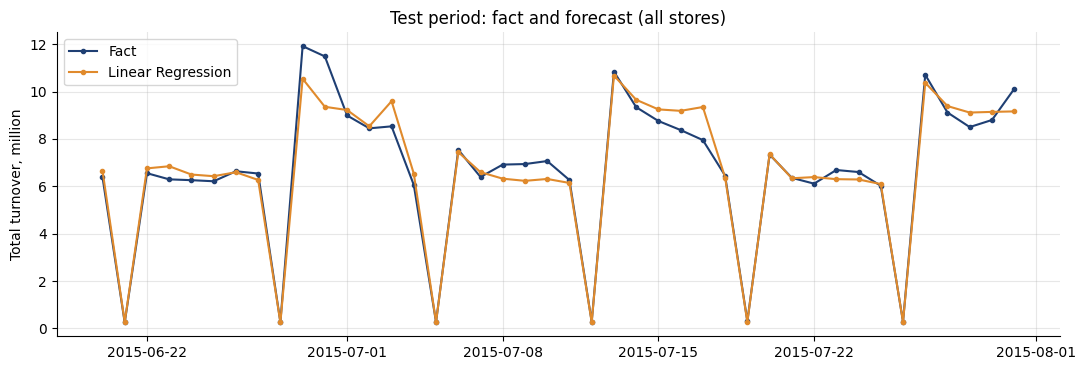

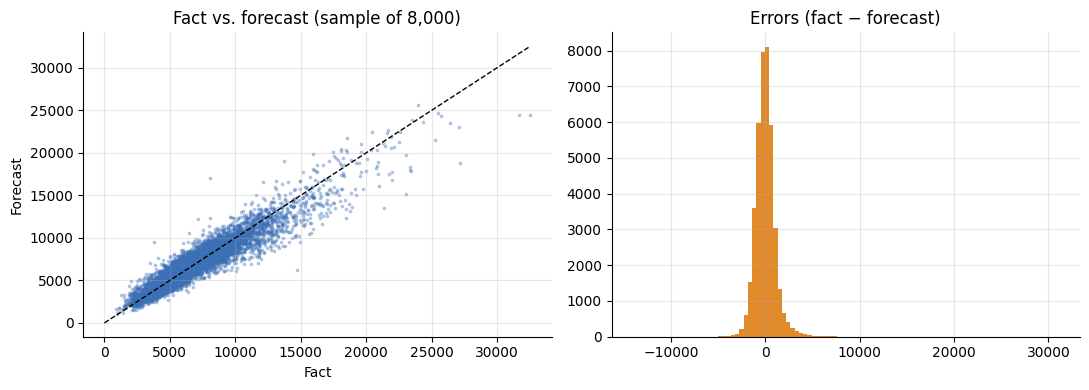

In [ ]:
pred_df = test_df[["Store", "Date", "Sales"]].copy()
pred_df["pred_LR"] = pred_te

daily = pred_df.groupby("Date")[["Sales", "pred_LR"]].sum() / 1e6
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily["Sales"], marker="o", ms=3, label="Fact", color="#1f3f73")
ax.plot(daily.index, daily["pred_LR"], marker="o", ms=3, label="Linear Regression", color="#e08a2c")
ax.set_ylabel("Total turnover, million"); ax.set_title("Test period: fact and forecast (all stores)"); ax.legend()
savefig("fig_lr_actual_vs_pred_daily")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
s = pred_df.sample(8000, random_state=SEED)
ax[0].scatter(s["Sales"], s["pred_LR"], s=3, alpha=.3, color="#3b6fb6")
lim = [0, max(s["Sales"].max(), s["pred_LR"].max())]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set_xlabel("Fact"); ax[0].set_ylabel("Forecast"); ax[0].set_title("Fact vs. forecast (sample of 8,000)")
ax[1].hist(pred_df["Sales"] - pred_df["pred_LR"], bins=100, color="#e08a2c"); ax[1].set_title("Errors (fact − forecast)")
savefig("fig_lr_scatter_residuals")

## 6. Summary table and saving

In [ ]:
summary = pd.DataFrame(results).T[["MAE", "RMSE", "MAPE", "R2", "n", "n_MAPE"]].round(3)
display(summary)
summary.to_csv(f"{TAB_DIR}/metrics_stage3_lr_and_naive.csv")
cv_lr.to_csv(f"{TAB_DIR}/cv_lr_folds.csv")

try:
    pred_df.to_parquet(os.path.join(OUT_DIR, "pred_LR.parquet"), index=False)
except ImportError:
    pred_df.to_pickle(os.path.join(OUT_DIR, "pred_LR.pkl"))
print("LR forecasts are saved in", OUT_DIR)

,MAE,RMSE,MAPE,R2,n,n_MAPE
Naive: Sales 7 days ago,2191.872,2830.126,32.094,0.142,40282.0,40282.0
Naive: Sales 14 days ago,806.482,1208.006,11.669,0.844,40282.0,40282.0
Naive: mean of last 28 days,1443.818,1885.534,23.009,0.619,40282.0,40282.0
Linear Regression,765.108,1088.565,11.749,0.873,40282.0,40282.0


LR forecasts are saved in /content/drive/MyDrive/rossmann/processed


# Этап 4. Random Forest and XGBoost: random search + final test score


In [ ]:
QUICK        = False
N_ITER       = 10
RF_FRAC      = 0.15
XGB_FRAC     = 0.50
RF_N_JOBS    = -1
USE_GPU      = shutil.which("nvidia-smi") is not None
RAM_LIMIT_GB = 9.0
if QUICK:
    N_ITER, RF_FRAC, XGB_FRAC = 2, 0.03, 0.03
TAG = "quick_" if QUICK else ""

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", __import__("scipy").__version__)   # -> Раздел 3.6 статьи
print("xgboost", xgb.__version__, "| GPU:", USE_GPU, "| QUICK:", QUICK, "| N_ITER:", N_ITER,
      "| RF_FRAC:", RF_FRAC, "| XGB_FRAC:", XGB_FRAC, "| CPU cores:", os.cpu_count())

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1 | scipy 1.16.3
xgboost 3.4.1 | GPU: False | QUICK: False | N_ITER: 10 | RF_FRAC: 0.15 | XGB_FRAC: 0.5 | CPU cores: 2


## 1. Data, metrics, folds

In [ ]:
def load_df(name):
    p = os.path.join(OUT_DIR, name + ".parquet")
    return pd.read_parquet(p) if os.path.exists(p) else pd.read_pickle(os.path.join(OUT_DIR, name + ".pkl"))

train_df, test_df = load_df("train_processed"), load_df("test_processed")
GROUPS = json.load(open(os.path.join(OUT_DIR, "feature_groups.json")))
PARAMS = json.load(open(os.path.join(OUT_DIR, "preproc_params.json")))
FEATURES = [c for g in GROUPS.values() for c in g]
TEST_START = pd.Timestamp(PARAMS["test_start"])

X_tr, y_tr = train_df[FEATURES].to_numpy(np.float32), train_df["Sales"].to_numpy(float)
X_te, y_te = test_df[FEATURES].to_numpy(np.float32),  test_df["Sales"].to_numpy(float)
print("train", X_tr.shape, "| test", X_te.shape)

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); pos = y > 0
    return {"MAE": float(np.mean(np.abs(y - p))), "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
            "MAPE": float(100 * np.mean(np.abs((y[pos] - p[pos]) / y[pos]))),
            "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
            "n": int(len(y)), "n_MAPE": int(pos.sum())}

N_FOLDS, VAL_DAYS = 4, 42
dates = train_df["Date"].to_numpy()
folds = []
for k in range(N_FOLDS):
    v_start = TEST_START - pd.Timedelta(days=VAL_DAYS * (N_FOLDS - k))
    v_end = v_start + pd.Timedelta(days=VAL_DAYS)
    tr_idx = np.where(dates < np.datetime64(v_start))[0]
    va_idx = np.where((dates >= np.datetime64(v_start)) & (dates < np.datetime64(v_end)))[0]
    folds.append((tr_idx, va_idx))

def subsample(idx, frac, seed):
    """A random subsample of the rows in the TRAINING part of the fold (validation is always complete)."""
    if frac >= 1: return idx
    r = np.random.RandomState(seed)
    return np.sort(r.choice(idx, size=max(1000, int(frac * len(idx))), replace=False))

def fold_subsamples(frac):
    return [subsample(tr, frac, SEED + k) for k, (tr, _) in enumerate(folds)]

train (804110, 35) | test (40282, 35)


## 2. General random search function with progress tracking


In [ ]:
def run_search(name, candidates, evaluate_candidate):
    """evaluate_candidate(params) -> dict(fold_rmse=[...], extra=...). Progress is written to the file after each configuration."""
    path = os.path.join(OUT_DIR, f"{TAG}search_{name}.json")
    done = json.load(open(path)) if os.path.exists(path) else []
    for i, params in enumerate(candidates):
        if i < len(done):
            continue
        t0 = time.time()
        out = evaluate_candidate(params)
        rec = {"id": i, "params": params, "fold_rmse": out["fold_rmse"],
               "mean_rmse": float(np.mean(out["fold_rmse"])), "sec": round(time.time() - t0, 1),
               **{k: v for k, v in out.items() if k != "fold_rmse"}}
        done.append(rec)
        json.dump(done, open(path, "w"), indent=1, default=float)
        print(f"[{name}] {i+1}/{len(candidates)}  CV-RMSE={rec['mean_rmse']:.1f}  "
              f"({rec['sec']} c)  {params}")
    res = pd.DataFrame(done)
    res = res.sort_values("mean_rmse").reset_index(drop=True)
    return res

## 3. Random Forest: hyperparameter search (Table 4)

In [ ]:
rf_space = {
    "n_estimators":      randint(100, 301),
    "max_depth":         randint(10, 31),
    "min_samples_split": randint(2, 21),
    "max_features":      ["sqrt", 0.5, 1.0],
}
rf_cands = [{k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
            for p in ParameterSampler(rf_space, n_iter=N_ITER, random_state=SEED)]
rf_subs = fold_subsamples(RF_FRAC)

### 3.1 Search time estimation (measured on 20 trees, then extrapolated roughly, ±50%)

RF time depends heavily on `max_features`: with 1.0, the tree is built many times longer than with `sqrt`.

In [ ]:
t_per_tree = {}
for mf in ["sqrt", 0.5, 1.0]:
    t0 = time.time()
    RandomForestRegressor(n_estimators=20, max_depth=20, min_samples_split=8, max_features=mf,
                          n_jobs=RF_N_JOBS, random_state=SEED).fit(X_tr[rf_subs[0]], y_tr[rf_subs[0]])
    t_per_tree[mf] = (time.time() - t0) / 20
    print(f"max_features={mf!s:>5}: {t_per_tree[mf]:.2f} c on the tree (subsample {len(rf_subs[0]):,} lines)")

est_search_min = sum(4 * p["n_estimators"] * t_per_tree[p["max_features"]] * 1.1 for p in rf_cands) / 60
print(f"\nRF search time estimation ({len(rf_cands)} configurations × 4 folds): ~{est_search_min:.0f} min")
print("If this takes too long, reduce RF_FRAC or N_ITER (and delete search_RF.json), or run it on a machine with a larger number of cores.")

max_features= sqrt: 0.24 c on the tree (subsample 97,423 lines)
max_features=  0.5: 0.61 c on the tree (subsample 97,423 lines)
max_features=  1.0: 1.18 c on the tree (subsample 97,423 lines)

RF search time estimation (10 configurations × 4 folds): ~99 min
If this takes too long, reduce RF_FRAC or N_ITER (and delete search_RF.json), or run it on a machine with a larger number of cores.


In [ ]:
def eval_rf(params):
    rmses = []
    for (tr_idx, va_idx), sub in zip(folds, rf_subs):
        m = RandomForestRegressor(**params, n_jobs=RF_N_JOBS, random_state=SEED)
        m.fit(X_tr[sub], y_tr[sub])
        rmses.append(metrics(y_tr[va_idx], m.predict(X_tr[va_idx]))["RMSE"])
    return {"fold_rmse": rmses}

rf_res = run_search("RF", rf_cands, eval_rf)
display(rf_res[["id", "mean_rmse", "sec", "params"]].head(10))
rf_best = rf_res.loc[0, "params"]
print("The best RF parameters:", rf_best)

[RF] 1/10  CV-RMSE=960.5  (157.2 c)  {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_split': 16, 'n_estimators': 206}
[RF] 2/10  CV-RMSE=948.5  (173.3 c)  {'max_depth': 17, 'max_features': 'sqrt', 'min_samples_split': 8, 'n_estimators': 221}
[RF] 3/10  CV-RMSE=965.4  (1031.4 c)  {'max_depth': 28, 'max_features': 1.0, 'min_samples_split': 12, 'n_estimators': 187}
[RF] 4/10  CV-RMSE=968.0  (1159.6 c)  {'max_depth': 30, 'max_features': 1.0, 'min_samples_split': 3, 'n_estimators': 187}
[RF] 5/10  CV-RMSE=932.6  (639.1 c)  {'max_depth': 21, 'max_features': 0.5, 'min_samples_split': 7, 'n_estimators': 229}
[RF] 6/10  CV-RMSE=945.8  (150.5 c)  {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_split': 13, 'n_estimators': 157}
[RF] 7/10  CV-RMSE=950.8  (139.7 c)  {'max_depth': 21, 'max_features': 'sqrt', 'min_samples_split': 18, 'n_estimators': 158}
[RF] 8/10  CV-RMSE=965.0  (1501.3 c)  {'max_depth': 19, 'max_features': 1.0, 'min_samples_split': 16, 'n_estimators': 289}
[RF] 9/10  C

,id,mean_rmse,sec,params
0,4,932.563378,639.1,"{'max_depth': 21, 'max_features': 0.5, 'min_sa..."
1,5,945.790856,150.5,"{'max_depth': 30, 'max_features': 'sqrt', 'min..."
2,1,948.540912,173.3,"{'max_depth': 17, 'max_features': 'sqrt', 'min..."
3,6,950.773463,139.7,"{'max_depth': 21, 'max_features': 'sqrt', 'min..."
4,9,955.166939,209.5,"{'max_depth': 16, 'max_features': 'sqrt', 'min..."
5,0,960.463313,157.2,"{'max_depth': 16, 'max_features': 'sqrt', 'min..."
6,7,964.969140,1501.3,"{'max_depth': 19, 'max_features': 1.0, 'min_sa..."
7,2,965.404418,1031.4,"{'max_depth': 28, 'max_features': 1.0, 'min_sa..."
8,3,967.985481,1159.6,"{'max_depth': 30, 'max_features': 1.0, 'min_sa..."
9,8,968.900155,904.3,"{'max_depth': 28, 'max_features': 1.0, 'min_sa..."


The best RF parameters: {'max_depth': 21, 'max_features': 0.5, 'min_samples_split': 7, 'n_estimators': 229}


## 4. Random Forest: final training on the entire train set and evaluation on the test set.


In [ ]:
FINAL_N = len(X_tr) if not QUICK else int(0.1 * len(X_tr))
final_idx = np.sort(np.random.RandomState(SEED).choice(len(X_tr), FINAL_N, replace=False)) if QUICK else np.arange(len(X_tr))
Xf, yf = X_tr[final_idx], y_tr[final_idx]

probe = RandomForestRegressor(**{**rf_best, "n_estimators": 1}, n_jobs=1, random_state=SEED).fit(Xf, yf)
nodes = probe.estimators_[0].tree_.node_count
est_gb = nodes * 72 * rf_best["n_estimators"] / 1e9
print(f"Nodes in one tree: {nodes:,} → forest memory estimate from {rf_best['n_estimators']} trees: {est_gb:.1f} GB")
est_fit_min = rf_best["n_estimators"] * t_per_tree[rf_best["max_features"]] * (len(Xf) / len(rf_subs[0])) * 1.3 / 60
print(f"Rough estimate of the time required for the final RF training: ~{est_fit_min:.0f} min")
rf_max_samples = None
if est_gb > RAM_LIMIT_GB:
    rf_max_samples = round(min(1.0, 0.8 * RAM_LIMIT_GB / est_gb), 2)
    print(f"Too much. I’m enabling max_samples={rf_max_samples}.")
del probe

t0 = time.time()
rf_final = RandomForestRegressor(**rf_best, max_samples=rf_max_samples, n_jobs=RF_N_JOBS, random_state=SEED).fit(Xf, yf)
rf_fit_time = time.time() - t0
pred_rf = rf_final.predict(X_te)
res_rf = metrics(y_te, pred_rf)
print("RF training time: %.1f min" % (rf_fit_time / 60)); print({k: round(v, 3) for k, v in res_rf.items()})

Nodes in one tree: 142,197 → forest memory estimate from 229 trees: 2.3 GB
Rough estimate of the time required for the final RF training: ~25 min
RF training time: 24.6 min
{'MAE': 558.032, 'RMSE': 816.392, 'MAPE': 8.339, 'R2': 0.929, 'n': 40282, 'n_MAPE': 40282}


## 5.XGBoost: hyperparameter search (Table 4)

Number of trees: maximum 1000 rounds + early stopping (50 rounds) **based on the fold validation window** only within CV.

For the final model, we take the average of best_iteration across the folds of the best configuration, **without** early stopping and without the test set.

In [ ]:
xgb_space = {
    "learning_rate": loguniform(0.01, 0.3),
    "max_depth":     randint(3, 11),
    "subsample":     uniform(0.6, 0.4),
    "reg_alpha":     uniform(0, 10),
    "reg_lambda":    uniform(0, 10),
}
xgb_cands = [{k: (float(v) if k in ("learning_rate", "subsample", "reg_alpha", "reg_lambda") else int(v))
              for k, v in p.items()} for p in ParameterSampler(xgb_space, n_iter=N_ITER, random_state=SEED)]
xgb_subs = fold_subsamples(XGB_FRAC)

def xgb_model(params, n_estimators, early_stopping=None):
    return xgb.XGBRegressor(**params, n_estimators=n_estimators, tree_method="hist",
                            device="cuda" if USE_GPU else "cpu", n_jobs=-1, random_state=SEED,
                            eval_metric="rmse", early_stopping_rounds=early_stopping)

def eval_xgb(params):
    rmses, iters = [], []
    for (tr_idx, va_idx), sub in zip(folds, xgb_subs):
        m = xgb_model(params, 1000, early_stopping=50)
        m.fit(X_tr[sub], y_tr[sub], eval_set=[(X_tr[va_idx], y_tr[va_idx])], verbose=False)
        rmses.append(float(m.best_score)); iters.append(int(m.best_iteration) + 1)
    return {"fold_rmse": rmses, "best_rounds": iters}

xgb_res = run_search("XGB", xgb_cands, eval_xgb)
display(xgb_res[["id", "mean_rmse", "sec", "best_rounds", "params"]].head(10))
xgb_best = xgb_res.loc[0, "params"]
xgb_rounds = int(round(np.mean(xgb_res.loc[0, "best_rounds"])))
print("The best parameters XGB:", xgb_best, "| rounds:", xgb_rounds)

[XGB] 1/10  CV-RMSE=894.0  (93.0 c)  {'learning_rate': 0.03574712922600244, 'max_depth': 7, 'reg_alpha': 1.834347898661638, 'reg_lambda': 7.796910002727692, 'subsample': 0.8387400631785948}
[XGB] 2/10  CV-RMSE=886.5  (86.9 c)  {'learning_rate': 0.04555636200065778, 'max_depth': 9, 'reg_alpha': 0.5808361216819946, 'reg_lambda': 8.661761457749352, 'subsample': 0.8404460046972835}
[XGB] 3/10  CV-RMSE=906.2  (36.6 c)  {'learning_rate': 0.11114989443094977, 'max_depth': 8, 'reg_alpha': 0.5641157902710026, 'reg_lambda': 7.219987722668248, 'subsample': 0.9754210836063001}
[XGB] 4/10  CV-RMSE=911.4  (161.6 c)  {'learning_rate': 0.010026522473407051, 'max_depth': 6, 'reg_alpha': 1.8340450985343382, 'reg_lambda': 3.0424224295953772, 'subsample': 0.8099025726528951}
[XGB] 5/10  CV-RMSE=936.1  (117.7 c)  {'learning_rate': 0.04345454109729477, 'max_depth': 3, 'reg_alpha': 5.2477466025838915, 'reg_lambda': 3.9986097171525548, 'subsample': 0.6186662652854461}
[XGB] 6/10  CV-RMSE=927.5  (33.3 c)  {'le

,id,mean_rmse,sec,best_rounds,params
0,1,886.480012,86.9,"[245, 359, 291, 243]","{'learning_rate': 0.04555636200065778, 'max_de..."
1,6,892.532788,92.4,"[150, 146, 190, 198]","{'learning_rate': 0.05748924681991978, 'max_de..."
2,0,893.970360,93.0,"[502, 499, 532, 419]","{'learning_rate': 0.03574712922600244, 'max_de..."
3,8,894.097213,181.3,"[491, 507, 548, 539]","{'learning_rate': 0.028180680291847244, 'max_d..."
4,9,895.099420,101.5,"[163, 113, 129, 184]","{'learning_rate': 0.07962309016748462, 'max_de..."
5,2,906.164679,36.6,"[101, 128, 115, 119]","{'learning_rate': 0.11114989443094977, 'max_de..."
6,3,911.360306,161.6,"[938, 993, 1000, 1000]","{'learning_rate': 0.010026522473407051, 'max_d..."
7,7,913.694369,108.5,"[468, 999, 695, 706]","{'learning_rate': 0.04628518674713462, 'max_de..."
8,5,927.452962,33.3,"[27, 36, 67, 33]","{'learning_rate': 0.27438159337282275, 'max_de..."
9,4,936.074367,117.7,"[1000, 981, 994, 775]","{'learning_rate': 0.04345454109729477, 'max_de..."


The best parameters XGB: {'learning_rate': 0.04555636200065778, 'max_depth': 9, 'reg_alpha': 0.5808361216819946, 'reg_lambda': 8.661761457749352, 'subsample': 0.8404460046972835} | rounds: 284


## 6.XGBoost: final training on the entire train set and evaluation on the test set.

In [ ]:
t0 = time.time()
xgb_final = xgb_model(xgb_best, xgb_rounds).fit(Xf, yf, verbose=False)
xgb_fit_time = time.time() - t0
pred_xgb = xgb_final.predict(X_te)
res_xgb = metrics(y_te, pred_xgb)
print("XGB training time: %.1f min" % (xgb_fit_time / 60)); print({k: round(v, 3) for k, v in res_xgb.items()})

XGB training time: 0.6 min
{'MAE': 564.437, 'RMSE': 816.956, 'MAPE': 8.387, 'R2': 0.928, 'n': 40282, 'n_MAPE': 40282}


## 7. Summary table (RQ1) and relative improvement compared to LR (RQ3, overall level)

In [ ]:
lr = Pipeline([("sc", StandardScaler()), ("ols", LinearRegression())]).fit(X_tr, y_tr)
pred_lr = lr.predict(X_te)

rows_ = {
    "Naive: Sales 14 days ago":   metrics(y_te, test_df["Sales_lag14"]),
    "Naive: mean of last 28 days": metrics(y_te, test_df["Sales_rmean28"]),
    "Linear Regression":          metrics(y_te, pred_lr),
    "Random Forest":              res_rf,
    "XGBoost":                    res_xgb,
}
summary = pd.DataFrame(rows_).T[["MAE", "RMSE", "MAPE", "R2"]]
summary["MAE vs LR, %"]  = 100 * (summary.loc["Linear Regression", "MAE"]  - summary["MAE"])  / summary.loc["Linear Regression", "MAE"]
summary["RMSE vs LR, %"] = 100 * (summary.loc["Linear Regression", "RMSE"] - summary["RMSE"]) / summary.loc["Linear Regression", "RMSE"]
summary["fit_time_min"] = pd.Series({"Linear Regression": np.nan, "Random Forest": rf_fit_time / 60, "XGBoost": xgb_fit_time / 60})
display(summary.round(3))
summary.round(4).to_csv(f"{TAB_DIR}/{TAG}metrics_main.csv")

,MAE,RMSE,MAPE,R2,"MAE vs LR, %","RMSE vs LR, %",fit_time_min
Naive: Sales 14 days ago,806.482,1208.006,11.669,0.844,-5.408,-10.972,NaN
Naive: mean of last 28 days,1443.818,1885.534,23.009,0.619,-88.708,-73.213,NaN
Linear Regression,765.108,1088.565,11.749,0.873,0.000,0.000,NaN
Random Forest,558.032,816.392,8.339,0.929,27.065,25.003,24.600
XGBoost,564.437,816.956,8.387,0.928,26.228,24.951,0.617


## 8. Graph: fact and forecasts for all models in the test.

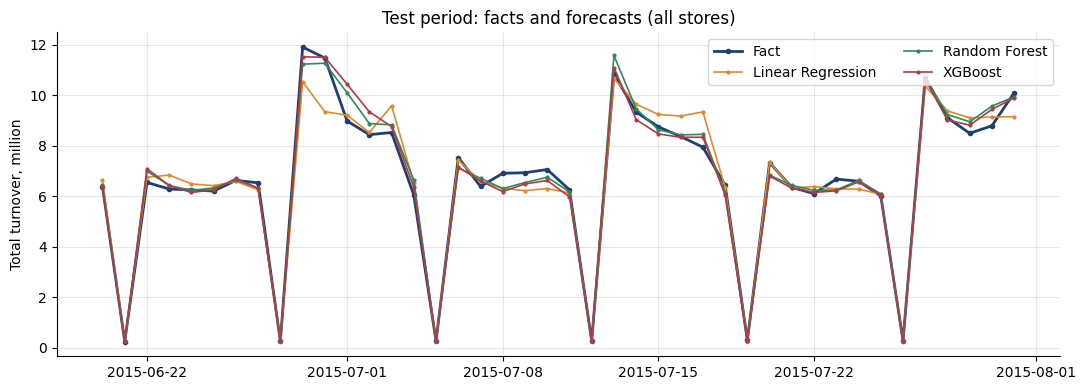

In [ ]:
pred_df = test_df[["Store", "Date", "Sales"]].copy()
pred_df["pred_LR"], pred_df["pred_RF"], pred_df["pred_XGB"] = pred_lr, pred_rf, pred_xgb
daily = pred_df.groupby("Date")[["Sales", "pred_LR", "pred_RF", "pred_XGB"]].sum() / 1e6

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["Sales"], "o-", ms=3, lw=2, color="#1f3f73", label="Fact")
for c, col, lab in [("pred_LR", "#e08a2c", "Linear Regression"), ("pred_RF", "#2e8b57", "Random Forest"), ("pred_XGB", "#b23a48", "XGBoost")]:
    ax.plot(daily.index, daily[c], "o-", ms=2, lw=1.2, color=col, label=lab)
ax.set_ylabel("Total turnover, million"); ax.set_title("Test period: facts and forecasts (all stores)"); ax.legend(ncol=2)
savefig("fig_models_actual_vs_pred_daily")

## 9. Saving the results

In [ ]:
rf_res.to_csv(f"{TAB_DIR}/{TAG}search_RF.csv", index=False)
xgb_res.to_csv(f"{TAB_DIR}/{TAG}search_XGB.csv", index=False)
best = {"RF": {**rf_best, "max_samples": rf_max_samples, "fit_time_min": rf_fit_time / 60},
        "XGB": {**xgb_best, "n_estimators": xgb_rounds, "fit_time_min": xgb_fit_time / 60},
        "settings": {"N_ITER": N_ITER, "RF_FRAC": RF_FRAC, "XGB_FRAC": XGB_FRAC, "QUICK": QUICK,
                     "xgboost": xgb.__version__, "GPU": USE_GPU}}
json.dump(best, open(os.path.join(OUT_DIR, f"{TAG}best_params.json"), "w"), indent=1, default=float)
try:
    pred_df.to_parquet(os.path.join(OUT_DIR, f"{TAG}pred_all.parquet"), index=False)
except ImportError:
    pred_df.to_pickle(os.path.join(OUT_DIR, f"{TAG}pred_all.pkl"))
print("Saved in:", [f for f in sorted(os.listdir(OUT_DIR)) if f.startswith(TAG or "best") or "pred_all" in f])

Saved in: ['best_params.json', 'pred_all.parquet']


# Stage 5. Contribution of feature groups (RQ2): permutation importance and ablation

Take the hyperparameters from Stage 4 (`best_params.json`) **don’t retrain the model** (Section 3.5).

1. Retrain LR / RF / XGBoost on the full set of features and compare with the saved predictions from Stage 4.
2. **Permutation importance on the test**: for individual features (3 repetitions) and for groups (5 repetitions), RMSE growth.
3. **Group ablation**: the model is retrained without one of the 4 groups (Table 3), hyperparameters remain the same.


In [ ]:
import os, json, time, shutil, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import xgboost as xgb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
QUICK = False
N_REPEATS_FEAT, N_REPEATS_GROUP = 3, 5
USE_GPU = shutil.which("nvidia-smi") is not None
if QUICK:
    N_REPEATS_FEAT, N_REPEATS_GROUP = 1, 2
TAG = "quick_" if QUICK else ""

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/rossmann/processed"
except ImportError:
    OUT_DIR = "processed"
RES_DIR = "/content/drive/MyDrive/rossmann" if os.path.exists("/content/drive/MyDrive") else "."
FIG_DIR, TAB_DIR = os.path.join(RES_DIR, "figures"), os.path.join(RES_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, TAG + name + ".png"), bbox_inches="tight"); plt.show()

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__,
      "| GPU:", USE_GPU, "| QUICK:", QUICK, "| CPU cores:", os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.16 | scikit-learn 1.6.1 | xgboost 3.4.1 | GPU: False | QUICK: False | CPU cores: 2


## 1. Data, parameters, functions

In [ ]:
def load_df(name):
    p = os.path.join(OUT_DIR, name + ".parquet")
    return pd.read_parquet(p) if os.path.exists(p) else pd.read_pickle(os.path.join(OUT_DIR, name + ".pkl"))

train_df, test_df = load_df("train_processed"), load_df("test_processed")
GROUPS = json.load(open(os.path.join(OUT_DIR, "feature_groups.json")))
FEATURES = [c for g in GROUPS.values() for c in g]
cands = ["quick_best_params.json", "best_params.json"] if QUICK else ["best_params.json"]
found = [os.path.join(OUT_DIR, n) for n in cands if os.path.exists(os.path.join(OUT_DIR, n))]
assert found, f"Не найден {cands} в {OUT_DIR}. Проверьте, что Этап 4 сохранил best_params.json на Диск."
best = json.load(open(found[0]))
print("Parameters from:", found[0])
rf_p  = {k: v for k, v in best["RF"].items()  if k != "fit_time_min"}
xgb_p = {k: v for k, v in best["XGB"].items() if k != "fit_time_min"}
print("RF :", rf_p); print("XGB:", xgb_p)

X_all, y_all = train_df[FEATURES].to_numpy(np.float32), train_df["Sales"].to_numpy(float)
X_te, y_te = test_df[FEATURES].to_numpy(np.float32), test_df["Sales"].to_numpy(float)
if QUICK:
    sel = np.sort(np.random.RandomState(SEED).choice(len(X_all), int(0.1 * len(X_all)), replace=False))
    X_fit, y_fit = X_all[sel], y_all[sel]
else:
    X_fit, y_fit = X_all, y_all
print("fit:", X_fit.shape, "| test:", X_te.shape)

col_idx = {f: i for i, f in enumerate(FEATURES)}
group_idx = {g: [col_idx[c] for c in cols] for g, cols in GROUPS.items()}

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); pos = y > 0
    return {"MAE": float(np.mean(np.abs(y - p))), "RMSE": rmse(y, p),
            "MAPE": float(100 * np.mean(np.abs((y[pos] - p[pos]) / y[pos]))),
            "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))}

def make_model(kind):
    if kind == "LR":  return Pipeline([("sc", StandardScaler()), ("ols", LinearRegression())])
    if kind == "RF":  return RandomForestRegressor(**rf_p, n_jobs=-1, random_state=SEED)
    if kind == "XGB": return xgb.XGBRegressor(**xgb_p, tree_method="hist", device="cuda" if USE_GPU else "cpu",
                                              n_jobs=-1, random_state=SEED)
MODELS = ["LR", "RF", "XGB"]

ABL_PATH = os.path.join(OUT_DIR, TAG + "stage5_ablation.json")
ABL = json.load(open(ABL_PATH)) if os.path.exists(ABL_PATH) else {}
def save_abl(): json.dump(ABL, open(ABL_PATH, "w"), indent=1)

Parameters from: /content/drive/MyDrive/rossmann/processed/best_params.json
RF : {'max_depth': 21, 'max_features': 0.5, 'min_samples_split': 7, 'n_estimators': 229, 'max_samples': None}
XGB: {'learning_rate': 0.04555636200065778, 'max_depth': 9, 'reg_alpha': 0.5808361216819946, 'reg_lambda': 8.661761457749352, 'subsample': 0.8404460046972835, 'n_estimators': 284}
fit: (804110, 35) | test: (40282, 35)


## 2. Retraining full models and checking reproducibility


In [ ]:
full, full_pred = {}, {}
for kind in MODELS:
    t0 = time.time()
    m = make_model(kind).fit(X_fit, y_fit)
    full[kind], full_pred[kind] = m, m.predict(X_te)
    sec = time.time() - t0
    ABL[f"{kind}|None"] = {**metrics(y_te, full_pred[kind]), "fit_sec": round(sec, 1)}
    print(f"{kind}: fit {sec/60:.1f} min | MAE={ABL[f'{kind}|None']['MAE']:.3f}  RMSE={ABL[f'{kind}|None']['RMSE']:.3f}")
    save_abl()

pa = os.path.join(OUT_DIR, TAG + "pred_all")
if os.path.exists(pa + ".parquet") or os.path.exists(pa + ".pkl"):
    saved = pd.read_parquet(pa + ".parquet") if os.path.exists(pa + ".parquet") else pd.read_pickle(pa + ".pkl")
    assert (saved["Store"].to_numpy() == test_df["Store"].to_numpy()).all() and (saved["Date"].to_numpy() == test_df["Date"].to_numpy()).all()
    print("\nReconciliation with the forecasts of Stage 4 (max. |difference| and MAE difference):")
    for kind in MODELS:
        d = np.abs(saved[f"pred_{kind}"].to_numpy() - full_pred[kind])
        dm = metrics(y_te, full_pred[kind])["MAE"] - metrics(y_te, saved[f"pred_{kind}"])["MAE"]
        print(f"  {kind}: max|Δ|={d.max():.4f} | ΔMAE={dm:+.4f}")
    if QUICK:
        print("  (QUICK: LR in Step 4 was trained on the entire train, but here it’s trained on 10% — the discrepancy is expected; RF and XGB should match if Step 4 was also in QUICK)")

LR: fit 0.0 min | MAE=765.108  RMSE=1088.565
RF: fit 28.3 min | MAE=558.032  RMSE=816.392
XGB: fit 0.6 min | MAE=564.437  RMSE=816.956

Reconciliation with the forecasts of Stage 4 (max. |difference| and MAE difference):
  LR: max|Δ|=0.0000 | ΔMAE=+0.0000
  RF: max|Δ|=0.0000 | ΔMAE=+0.0000
  XGB: max|Δ|=0.0000 | ΔMAE=+0.0000


## 3. Permutation importance on the test (Section 3.5)

The feature values are randomly shuffled, and the RMSE growth is measured (the higher the value, the more the model relies on the feature).

For groups, we shuffle **the entire rows** using the same permutation, so that the relationship within the group is preserved, and the importance of correlated lags is not “divided” among them.

In [ ]:
def perm_importance(predict, X, y, col_sets, n_repeats, seed):
    rng = np.random.RandomState(seed)
    base = rmse(y, predict(X))
    out = {}
    for name, idx in col_sets.items():
        d = []
        for _ in range(n_repeats):
            perm = rng.permutation(len(X)); Xp = X.copy(); Xp[:, idx] = X[perm][:, idx]
            d.append(rmse(y, predict(Xp)) - base)
        out[name] = d
    return base, out

t_pred = {}
for kind in MODELS:
    t0 = time.time(); full[kind].predict(X_te); t_pred[kind] = time.time() - t0
n_calls = len(FEATURES) * N_REPEATS_FEAT + len(GROUPS) * N_REPEATS_GROUP
print("The time of one predict:", {k: f"{v:.1f} c" for k, v in t_pred.items()})
print(f"Time estimation permutation importance: ~{sum(t_pred.values()) * n_calls / 60:.0f} min")

The time of one predict: {'LR': '0.0 c', 'RF': '2.5 c', 'XGB': '0.2 c'}
Time estimation permutation importance: ~6 min


In [ ]:
PERM_PATH = os.path.join(OUT_DIR, TAG + "stage5_perm.json")
PERM = json.load(open(PERM_PATH)) if os.path.exists(PERM_PATH) else {}
feat_sets  = {f: [i] for f, i in col_idx.items()}

for kind in MODELS:
    if kind in PERM:
        print(kind, "- It has already been calculated."); continue
    t0 = time.time()
    base, feat = perm_importance(full[kind].predict, X_te, y_te, feat_sets, N_REPEATS_FEAT, SEED)
    _,    grp  = perm_importance(full[kind].predict, X_te, y_te, group_idx, N_REPEATS_GROUP, SEED + 1)
    PERM[kind] = {"base_rmse": base, "features": feat, "groups": grp}
    json.dump(PERM, open(PERM_PATH, "w"), indent=1)
    print(f"{kind}: ready in {(time.time()-t0)/60:.1f} min (basic RMSE {base:.2f})")

LR: ready in 0.1 min (basic RMSE 1088.56)
RF: ready in 4.9 min (basic RMSE 816.39)
XGB: ready in 0.6 min (basic RMSE 816.96)


### 3.1 Tables and charts

Permutation importance By groups: RMSE growth (min. monetary units):


LR           RF          XGB     
                 mean  std    mean  std    mean  std
Temporal          5.8  0.3   224.3  3.3   277.4  2.5
Historical     2659.5  8.0  2975.0  5.2  2957.0  7.4
Promo_Holiday   690.5  4.2   854.9  5.8   818.2  6.1
Store             1.1  0.1     7.9  0.1    16.3  0.5

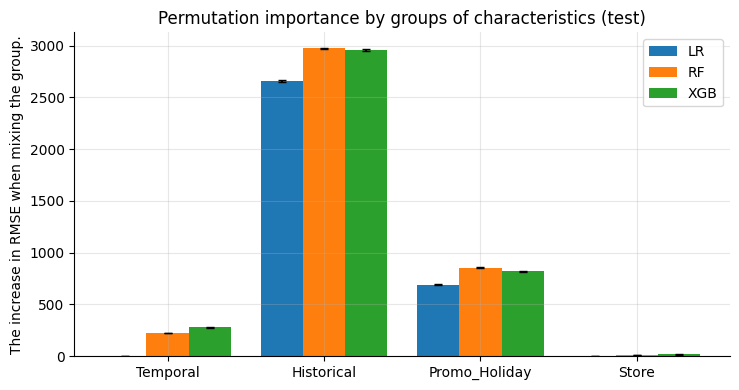

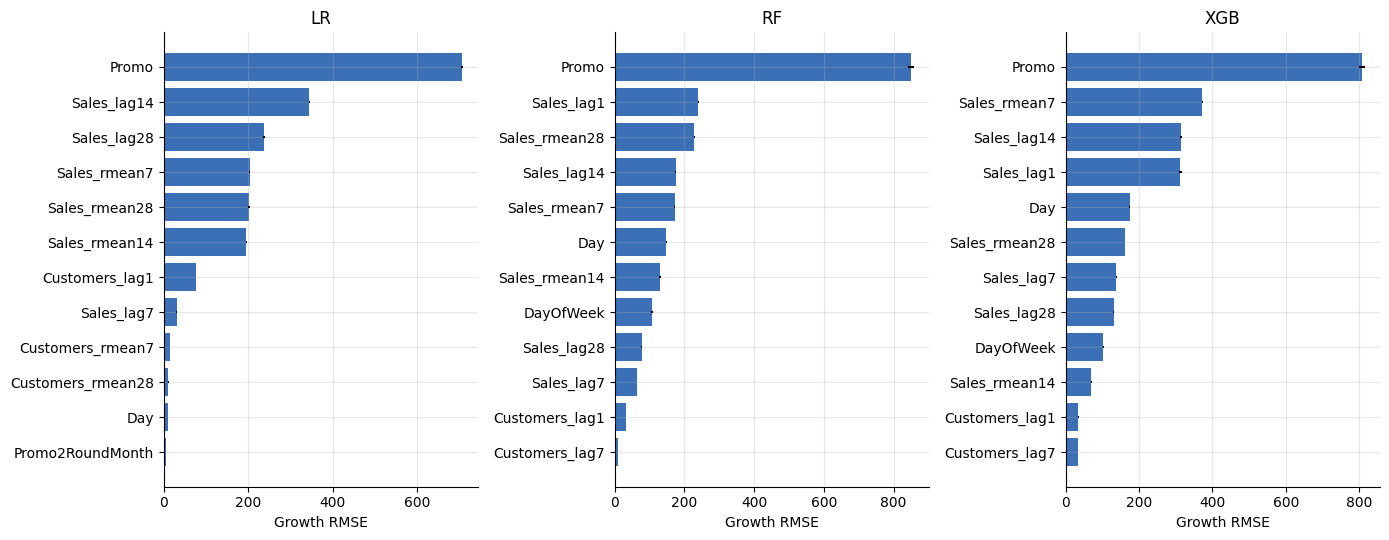

In [ ]:
def perm_table(level):
    cols = {}
    for kind in MODELS:
        d = PERM[kind][level]
        cols[(kind, "mean")] = {k: np.mean(v) for k, v in d.items()}
        cols[(kind, "std")]  = {k: np.std(v)  for k, v in d.items()}
    return pd.DataFrame(cols)

pg = perm_table("groups"); pf = perm_table("features")
pg.round(2).to_csv(f"{TAB_DIR}/{TAG}perm_groups.csv"); pf.round(2).to_csv(f"{TAB_DIR}/{TAG}perm_features.csv")
print("Permutation importance By groups: RMSE growth (min. monetary units):")
display(pg.round(1))

fig, ax = plt.subplots(figsize=(7.5, 4))
w, x = 0.27, np.arange(len(GROUPS))
for j, kind in enumerate(MODELS):
    ax.bar(x + (j - 1) * w, pg[(kind, "mean")].reindex(list(GROUPS)), w,
           yerr=pg[(kind, "std")].reindex(list(GROUPS)), capsize=3, label=kind)
ax.set_xticks(x); ax.set_xticklabels(list(GROUPS)); ax.set_ylabel("The increase in RMSE when mixing the group."); ax.legend()
ax.set_title("Permutation importance by groups of characteristics (test)")
savefig("fig_perm_groups")

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
for a, kind in zip(axes, MODELS):
    t = pf[(kind, "mean")].sort_values().tail(12)
    a.barh(t.index, t.values, xerr=pf[(kind, "std")].reindex(t.index).values, color="#3b6fb6"); a.set_title(kind)
    a.set_xlabel("Growth RMSE")
savefig("fig_perm_features_top12")

## 4. Ablation of feature groups (Section 3.5)

For each model and each group: retraining **without** the group, the same hyperparameters, the same chronology; comparison with the full model on the test set.

In [ ]:
for kind in ["RF"]:
    full.pop(kind, None)

for kind in MODELS:
    for g in GROUPS:
        key = f"{kind}|{g}"
        if key in ABL:
            print(key, "- It has already been calculated."); continue
        keep = [i for i, f in enumerate(FEATURES) if f not in GROUPS[g]]
        t0 = time.time()
        m = make_model(kind).fit(X_fit[:, keep], y_fit)
        ABL[key] = {**metrics(y_te, m.predict(X_te[:, keep])), "fit_sec": round(time.time() - t0, 1), "n_features": len(keep)}
        save_abl(); del m
        print(f"{key}: RMSE={ABL[key]['RMSE']:.2f}  MAE={ABL[key]['MAE']:.2f}  ({ABL[key]['fit_sec']/60:.1f} min)")

LR|Temporal: RMSE=1092.78  MAE=766.41  (0.0 min)
LR|Historical: RMSE=2647.17  MAE=1962.83  (0.0 min)
LR|Promo_Holiday: RMSE=1253.90  MAE=910.24  (0.0 min)
LR|Store: RMSE=1088.63  MAE=765.08  (0.0 min)
RF|Temporal: RMSE=900.42  MAE=611.44  (24.6 min)
RF|Historical: RMSE=1504.33  MAE=1048.05  (5.0 min)
RF|Promo_Holiday: RMSE=930.12  MAE=631.52  (25.6 min)
RF|Store: RMSE=819.55  MAE=560.68  (23.2 min)
XGB|Temporal: RMSE=900.35  MAE=613.19  (0.5 min)
XGB|Historical: RMSE=1535.58  MAE=1072.45  (0.4 min)
XGB|Promo_Holiday: RMSE=891.99  MAE=616.20  (0.5 min)
XGB|Store: RMSE=810.08  MAE=560.32  (0.5 min)


### 4.1 Final ablation table

,model,removed_group,MAE,RMSE,R2,ΔMAE,ΔRMSE,"ΔMAE, %","ΔRMSE, %"
0,LR,Temporal,766.41,1092.78,0.87,1.30,4.21,0.17,0.39
1,LR,Historical,1962.83,2647.17,0.25,1197.72,1558.60,156.54,143.18
2,LR,Promo_Holiday,910.24,1253.90,0.83,145.13,165.34,18.97,15.19
3,LR,Store,765.08,1088.63,0.87,-0.02,0.07,-0.00,0.01
4,RF,Temporal,611.44,900.42,0.91,53.41,84.03,9.57,10.29
5,RF,Historical,1048.05,1504.33,0.76,490.01,687.94,87.81,84.27
6,RF,Promo_Holiday,631.52,930.12,0.91,73.49,113.73,13.17,13.93
7,RF,Store,560.68,819.55,0.93,2.64,3.16,0.47,0.39
8,XGB,Temporal,613.19,900.35,0.91,48.75,83.40,8.64,10.21
9,XGB,Historical,1072.45,1535.58,0.75,508.02,718.63,90.00,87.96


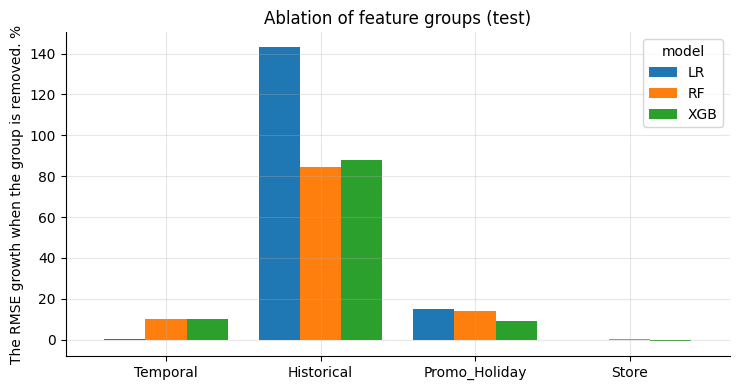

In [ ]:
rows = []
for kind in MODELS:
    base = ABL[f"{kind}|None"]
    for g in GROUPS:
        r = ABL[f"{kind}|{g}"]
        rows.append({"model": kind, "removed_group": g, "MAE": r["MAE"], "RMSE": r["RMSE"], "R2": r["R2"],
                     "ΔMAE": r["MAE"] - base["MAE"], "ΔRMSE": r["RMSE"] - base["RMSE"],
                     "ΔMAE, %": 100 * (r["MAE"] / base["MAE"] - 1), "ΔRMSE, %": 100 * (r["RMSE"] / base["RMSE"] - 1)})
abl = pd.DataFrame(rows)
abl.round(3).to_csv(f"{TAB_DIR}/{TAG}ablation.csv", index=False)
display(abl.round(2))

piv = abl.pivot(index="removed_group", columns="model", values="ΔRMSE, %").reindex(list(GROUPS))[MODELS]
fig, ax = plt.subplots(figsize=(7.5, 4))
piv.plot(kind="bar", ax=ax, width=0.8); ax.set_ylabel("The RMSE growth when the group is removed. %"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0); ax.set_title("Ablation of feature groups (test)")
savefig("fig_ablation_rmse_pct")

# Stage 6. RQ3: ensembles vs. linear model by store + statistical verification

1. Errors of each model **by store**; the proportion of stores where the ensemble performs better than LR. Distribution of improvements.
2. **Confidence intervals** (bootstrap) for the difference between models: by store and by day of the test period.
3. Wilcoxon test by store (RF vs LR, XGB vs LR, RF vs XGB).
4. Where the win is: by day of the week, `Promo`, store type, store size.

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")
SEED = 42
N_BOOT = 5000

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RES_DIR = "/content/drive/MyDrive/rossmann"
    OUT_DIR = os.path.join(RES_DIR, "processed")
except ImportError:
    RES_DIR, OUT_DIR = ".", "processed"
FIG_DIR, TAB_DIR = os.path.join(RES_DIR, "figures"), os.path.join(RES_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight"); plt.show()

def load_df(name):
    p = os.path.join(OUT_DIR, name + ".parquet")
    return pd.read_parquet(p) if os.path.exists(p) else pd.read_pickle(os.path.join(OUT_DIR, name + ".pkl"))

Mounted at /content/drive


## 1. Data

In [ ]:
pred = load_df("pred_all")
test_df = load_df("test_processed")
train_df = load_df("train_processed")
assert (pred["Store"].to_numpy() == test_df["Store"].to_numpy()).all() and (pred["Date"].to_numpy() == test_df["Date"].to_numpy()).all()

MODELS = ["LR", "RF", "XGB"]
d = pred[["Store", "Date", "Sales"]].copy()
for m in MODELS:
    d[f"ae_{m}"] = (pred["Sales"] - pred[f"pred_{m}"]).abs()
    d[f"se_{m}"] = (pred["Sales"] - pred[f"pred_{m}"]) ** 2
d["DayOfWeek"] = test_df["DayOfWeek"].astype(int).to_numpy()
d["Promo"] = test_df["Promo"].astype(int).to_numpy()
st_cols = [c for c in test_df.columns if c.startswith("StoreType_")]
d["StoreType"] = np.where(test_df[st_cols].sum(axis=1) == 0, "a",
                          test_df[st_cols].idxmax(axis=1).str.replace("StoreType_", "")).astype(str)
size = train_df.groupby("Store")["Sales"].mean()
d["SizeQ"] = pd.qcut(d["Store"].map(size), 4, labels=["Q1 (small)", "Q2", "Q3", "Q4 (large)"]).astype(str)
print(d.shape, "| stores:", d.Store.nunique(), "| days:", d.Date.nunique())

(40282, 13) | stores: 1115 | days: 42


## 2. Store-related errors (RQ3)

,model,metric,stores_better_than_LR_%,median_reduction_%,Q1_%,Q3_%,p5_%,p95_%,mean_%
0,RF,MAE,98.83,26.26,16.89,35.33,6.41,48.82,26.48
1,RF,RMSE,98.21,25.85,17.57,34.50,5.33,47.48,25.96
2,XGB,MAE,96.86,25.56,15.60,35.24,3.03,48.30,25.44
3,XGB,RMSE,95.96,25.83,16.18,34.95,1.58,46.95,25.20


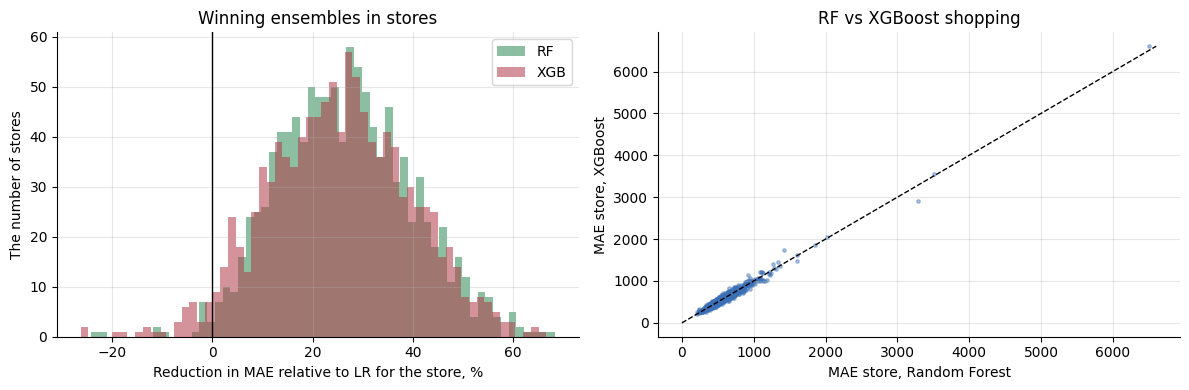

In [ ]:
g = d.groupby("Store")
store_tab = pd.DataFrame({"n": g.size()})
for m in MODELS:
    store_tab[f"MAE_{m}"]  = g[f"ae_{m}"].mean()
    store_tab[f"RMSE_{m}"] = np.sqrt(g[f"se_{m}"].mean())
for m in ["RF", "XGB"]:
    store_tab[f"MAE_red_{m}_%"]  = 100 * (1 - store_tab[f"MAE_{m}"]  / store_tab["MAE_LR"])
    store_tab[f"RMSE_red_{m}_%"] = 100 * (1 - store_tab[f"RMSE_{m}"] / store_tab["RMSE_LR"])
store_tab.round(3).to_csv(f"{TAB_DIR}/per_store_errors.csv")

rows = []
for m in ["RF", "XGB"]:
    for met in ["MAE", "RMSE"]:
        r = store_tab[f"{met}_red_{m}_%"]
        rows.append({"model": m, "metric": met, "stores_better_than_LR_%": 100 * (r > 0).mean(),
                     "median_reduction_%": r.median(), "Q1_%": r.quantile(.25), "Q3_%": r.quantile(.75),
                     "p5_%": r.quantile(.05), "p95_%": r.quantile(.95), "mean_%": r.mean()})
summ_store = pd.DataFrame(rows)
display(summ_store.round(2)); summ_store.round(3).to_csv(f"{TAB_DIR}/per_store_summary.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, col in [("RF", "#2e8b57"), ("XGB", "#b23a48")]:
    ax[0].hist(store_tab[f"MAE_red_{m}_%"], bins=60, alpha=.55, label=m, color=col)
ax[0].axvline(0, color="k", lw=1); ax[0].set_xlabel("Reduction in MAE relative to LR for the store, %"); ax[0].set_ylabel("The number of stores")
ax[0].set_title("Winning ensembles in stores"); ax[0].legend()
lim = [0, max(store_tab.MAE_RF.max(), store_tab.MAE_XGB.max())]
ax[1].scatter(store_tab.MAE_RF, store_tab.MAE_XGB, s=6, alpha=.4, color="#3b6fb6"); ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlabel("MAE store, Random Forest"); ax[1].set_ylabel("MAE store, XGBoost"); ax[1].set_title("RF vs XGBoost shopping")
savefig("fig_rq3_per_store")

## 3. Confidence intervals (bootstrap) and the Wilcoxon test


In [ ]:
def boot_ci(unit_col, n_boot=N_BOOT, seed=SEED):
    agg = d.groupby(unit_col).agg(n=("Sales", "size"), **{f"ae_{m}": (f"ae_{m}", "sum") for m in MODELS},
                                  **{f"se_{m}": (f"se_{m}", "sum") for m in MODELS})
    n = agg["n"].to_numpy(float); rng = np.random.RandomState(seed)
    idx = rng.randint(0, len(agg), size=(n_boot, len(agg)))
    N = n[idx].sum(1)
    mae  = {m: agg[f"ae_{m}"].to_numpy()[idx].sum(1) / N for m in MODELS}
    rmse = {m: np.sqrt(agg[f"se_{m}"].to_numpy()[idx].sum(1) / N) for m in MODELS}
    out = []
    pairs = [("LR", "RF"), ("LR", "XGB"), ("RF", "XGB")]
    for a, b in pairs:
        for met, arr in [("MAE", mae), ("RMSE", rmse)]:
            red = 100 * (1 - arr[b] / arr[a])
            pa = agg[f"{'ae' if met=='MAE' else 'se'}_{a}"].sum() / n.sum(); pb = agg[f"{'ae' if met=='MAE' else 'se'}_{b}"].sum() / n.sum()
            if met == "RMSE": pa, pb = np.sqrt(pa), np.sqrt(pb)
            out.append({"comparison": f"{b} vs {a}", "metric": met, "reduction_%": 100 * (1 - pb / pa),
                        "CI95_low": np.percentile(red, 2.5), "CI95_high": np.percentile(red, 97.5),
                        "unit": unit_col, "n_units": len(agg)})
    return pd.DataFrame(out)

ci_store = boot_ci("Store"); ci_day = boot_ci("Date")
ci = pd.concat([ci_store, ci_day], ignore_index=True)
ci.round(3).to_csv(f"{TAB_DIR}/bootstrap_ci.csv", index=False)
display(ci.round(2))
print("Interpretation: “b vs a” = by how many percent the error for b is lower than for a. If the interval includes 0, the difference is not proven.")

,comparison,metric,reduction_%,CI95_low,CI95_high,unit,n_units
0,RF vs LR,MAE,27.06,26.22,27.92,Store,1115
1,RF vs LR,RMSE,25.00,22.71,26.99,Store,1115
2,XGB vs LR,MAE,26.23,25.34,27.17,Store,1115
3,XGB vs LR,RMSE,24.95,22.33,27.15,Store,1115
4,XGB vs RF,MAE,-1.15,-1.64,-0.66,Store,1115
5,XGB vs RF,RMSE,-0.07,-0.80,0.70,Store,1115
6,RF vs LR,MAE,27.06,19.18,34.30,Date,42
7,RF vs LR,RMSE,25.00,15.28,34.25,Date,42
8,XGB vs LR,MAE,26.23,16.57,34.73,Date,42
9,XGB vs LR,RMSE,24.95,13.77,35.07,Date,42


Interpretation: “b vs a” = by how many percent the error for b is lower than for a. If the interval includes 0, the difference is not proven.


In [ ]:
wil = []
for a, b in [("LR", "RF"), ("LR", "XGB"), ("RF", "XGB")]:
    for met in ["MAE", "RMSE"]:
        x, y = store_tab[f"{met}_{a}"], store_tab[f"{met}_{b}"]
        stat, p = wilcoxon(x, y)
        wil.append({"comparison": f"{b} vs {a}", "metric": met, "median_diff (a−b)": float((x - y).median()),
                    "share_stores_b_better_%": 100 * float((y < x).mean()), "wilcoxon_p": float(p)})
wil = pd.DataFrame(wil); wil.to_csv(f"{TAB_DIR}/wilcoxon_per_store.csv", index=False)
display(wil.round(4))

,comparison,metric,median_diff (a−b),share_stores_b_better_%,wilcoxon_p
0,RF vs LR,MAE,184.5529,98.8341,0.0000
1,RF vs LR,RMSE,237.0409,98.2063,0.0000
2,XGB vs LR,MAE,177.2182,96.8610,0.0000
3,XGB vs LR,RMSE,228.0608,95.9641,0.0000
4,XGB vs RF,MAE,-6.9152,42.0628,0.0000
5,XGB vs RF,RMSE,-8.5215,44.0359,0.0016


## 4. Where is the gain: segments

,value,segment,n,MAE_LR,MAE_RF,MAE_XGB,MAE_red_RF_%,MAE_red_XGB_%
0,1,DayOfWeek,6682,787.2,713.1,668.3,9.4,15.1
1,2,DayOfWeek,6682,834.6,501.3,495.7,39.9,40.6
2,3,DayOfWeek,6682,672.4,583.4,629.7,13.2,6.4
3,4,DayOfWeek,6680,649.0,541.2,578.9,16.6,10.8
4,5,DayOfWeek,6681,842.6,511.4,514.6,39.3,38.9
5,6,DayOfWeek,6682,774.6,494.8,495.5,36.1,36.0
6,7,DayOfWeek,193,1810.1,662.2,699.3,63.4,61.4
7,0,Promo,23581,629.6,469.0,477.4,25.5,24.2
8,1,Promo,16701,956.4,683.7,687.3,28.5,28.1
9,a,StoreType,21694,768.8,557.5,562.7,27.5,26.8


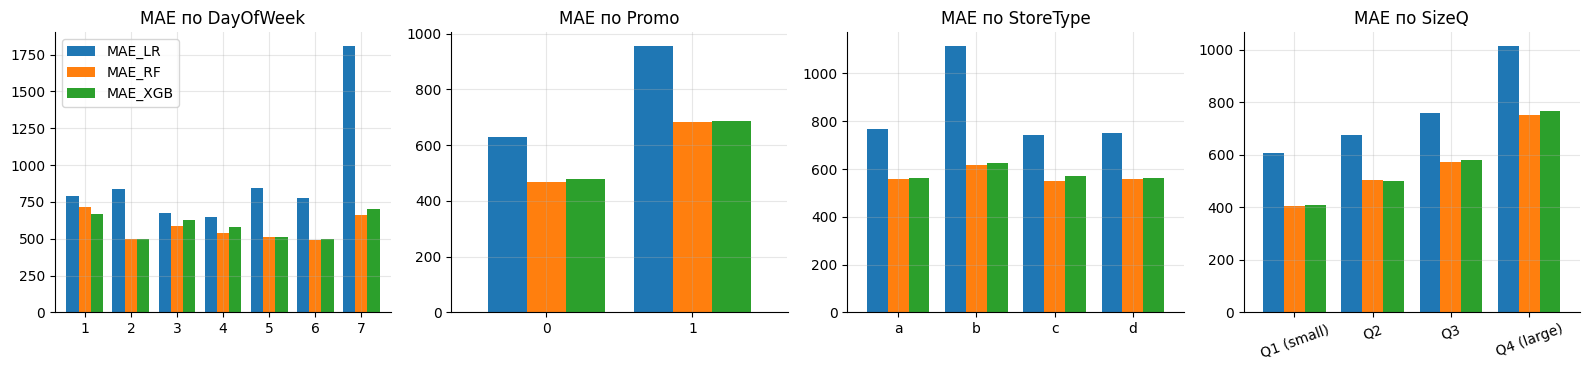

In [ ]:
def seg_table(col):
    gg = d.groupby(col)
    t = pd.DataFrame({"n": gg.size()})
    for m in MODELS: t[f"MAE_{m}"] = gg[f"ae_{m}"].mean()
    for m in ["RF", "XGB"]: t[f"MAE_red_{m}_%"] = 100 * (1 - t[f"MAE_{m}"] / t["MAE_LR"])
    t.insert(0, "segment", col); t.index = t.index.astype(str); return t.reset_index().rename(columns={col: "value"})

seg = pd.concat([seg_table(c) for c in ["DayOfWeek", "Promo", "StoreType", "SizeQ"]], ignore_index=True)
seg.round(2).to_csv(f"{TAB_DIR}/segments_mae.csv", index=False)
display(seg.round(1))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, c in zip(ax, ["DayOfWeek", "Promo", "StoreType", "SizeQ"]):
    t = seg[seg.segment == c].set_index("value")
    t[["MAE_LR", "MAE_RF", "MAE_XGB"]].plot(kind="bar", ax=a, width=.8, legend=(c == "DayOfWeek"))
    a.set_title(f"MAE по {c}"); a.set_xlabel(""); a.tick_params(axis="x", rotation=0 if c != "SizeQ" else 20)
savefig("fig_rq3_segments")

# Stage 6b. Checking the integrity of the baseline model: linear regression with a categorical calendar

In the main experiment, `DayOfWeek` and `Month` are provided to LR as **numbers**: the linear model sees “Friday = 5” and can only account for

the monotonic effect of the day of the week. Trees do not have this limitation. Here we check what part of the ensemble’s gain

The advantage over LR is explained precisely by this, and not by nonlinearity as such.

* **LR** — as in the main experiment (numerical `DayOfWeek`, `Month`);
* **LR+calendar** — `DayOfWeek` and `Month` in one-hot form;
* **LR+calendar+Promo×DoW** — additionally, the interaction of Promo with the day of the week.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
SEED, N_BOOT = 42, 5000

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RES_DIR = "/content/drive/MyDrive/rossmann"
    OUT_DIR = os.path.join(RES_DIR, "processed")
except ImportError:
    RES_DIR, OUT_DIR = ".", "processed"
FIG_DIR, TAB_DIR = os.path.join(RES_DIR, "figures"), os.path.join(RES_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

def load_df(name):
    p = os.path.join(OUT_DIR, name + ".parquet")
    return pd.read_parquet(p) if os.path.exists(p) else pd.read_pickle(os.path.join(OUT_DIR, name + ".pkl"))

train_df, test_df, pred = load_df("train_processed"), load_df("test_processed"), load_df("pred_all")
GROUPS = json.load(open(os.path.join(OUT_DIR, "feature_groups.json")))
FEATURES = [c for g in GROUPS.values() for c in g]
assert (pred["Store"].to_numpy() == test_df["Store"].to_numpy()).all() and (pred["Date"].to_numpy() == test_df["Date"].to_numpy()).all()
y_tr, y_te = train_df["Sales"].to_numpy(float), test_df["Sales"].to_numpy(float)

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); pos = y > 0
    return {"MAE": float(np.mean(np.abs(y - p))), "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
            "MAPE": float(100 * np.mean(np.abs((y[pos] - p[pos]) / y[pos]))),
            "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))}

Mounted at /content/drive


## 1. Three linear models

In [ ]:
def design(df, calendar_onehot=False, promo_dow=False):
    X = df[FEATURES].copy()
    if calendar_onehot:
        X = X.drop(columns=["DayOfWeek", "Month"])
        X = X.join(pd.get_dummies(df["DayOfWeek"].astype(int), prefix="DoW", drop_first=True, dtype=float))
        X = X.join(pd.get_dummies(df["Month"].astype(int), prefix="Mon", drop_first=True, dtype=float))
        if promo_dow:
            for c in [c for c in X.columns if c.startswith("DoW_")]:
                X[f"Promo_x_{c}"] = X["Promo"] * X[c]
    return X

variants = {"LR": dict(), "LR+calendar": dict(calendar_onehot=True), "LR+calendar+Promo×DoW": dict(calendar_onehot=True, promo_dow=True)}
res, preds = {}, {}
for name, kw in variants.items():
    Xtr = design(train_df, **kw); Xte = design(test_df, **kw).reindex(columns=Xtr.columns, fill_value=0.0)
    m = Pipeline([("sc", StandardScaler()), ("ols", LinearRegression())]).fit(Xtr, y_tr)
    preds[name] = m.predict(Xte); res[name] = metrics(y_te, preds[name])
    print(f"{name:26s} signs: {Xtr.shape[1]:3d} | MAE={res[name]['MAE']:.1f}  RMSE={res[name]['RMSE']:.1f}")

for m in ["RF", "XGB"]:
    res[m] = metrics(y_te, pred[f"pred_{m}"]); preds[m] = pred[f"pred_{m}"].to_numpy()

summary = pd.DataFrame(res).T
base = summary.loc["LR"]
summary["MAE vs LR, %"]  = 100 * (1 - summary["MAE"]  / base["MAE"])
summary["RMSE vs LR, %"] = 100 * (1 - summary["RMSE"] / base["RMSE"])
display(summary.round(3)); summary.round(4).to_csv(f"{TAB_DIR}/sensitivity_linear_baselines.csv")

LR                         signs:  35 | MAE=765.1  RMSE=1088.6
LR+calendar                signs:  50 | MAE=777.0  RMSE=1095.4
LR+calendar+Promo×DoW      signs:  56 | MAE=763.5  RMSE=1082.1


,MAE,RMSE,MAPE,R2,"MAE vs LR, %","RMSE vs LR, %"
LR,765.108,1088.565,11.749,0.873,0.000,0.000
LR+calendar,777.004,1095.362,12.003,0.871,-1.555,-0.624
LR+calendar+Promo×DoW,763.520,1082.102,11.806,0.875,0.208,0.594
RF,558.032,816.392,8.339,0.929,27.065,25.003
XGB,564.437,816.956,8.387,0.928,26.228,24.951


## 2. The performance of the ensembles relative to the strongest linear model + confidence intervals

In [ ]:
d = pred[["Store", "Date", "Sales"]].copy()
for k, v in preds.items():
    d[f"ae_{k}"], d[f"se_{k}"] = np.abs(d["Sales"] - v), (d["Sales"] - v) ** 2

def boot(unit, a, b, n_boot=N_BOOT, seed=SEED):
    agg = d.groupby(unit).agg(n=("Sales", "size"), ae_a=(f"ae_{a}", "sum"), ae_b=(f"ae_{b}", "sum"),
                              se_a=(f"se_{a}", "sum"), se_b=(f"se_{b}", "sum"))
    idx = np.random.RandomState(seed).randint(0, len(agg), size=(n_boot, len(agg)))
    N = agg["n"].to_numpy(float)[idx].sum(1); out = []
    for met in ["MAE", "RMSE"]:
        f = (lambda s: s) if met == "MAE" else np.sqrt
        pt = 100 * (1 - f(agg["ae_b" if met == "MAE" else "se_b"].sum() / agg["n"].sum()) / f(agg["ae_a" if met == "MAE" else "se_a"].sum() / agg["n"].sum()))
        va = f(agg["ae_a" if met == "MAE" else "se_a"].to_numpy()[idx].sum(1) / N)
        vb = f(agg["ae_b" if met == "MAE" else "se_b"].to_numpy()[idx].sum(1) / N)
        red = 100 * (1 - vb / va)
        out.append({"comparison": f"{b} vs {a}", "metric": met, "reduction_%": pt,
                    "CI95_low": np.percentile(red, 2.5), "CI95_high": np.percentile(red, 97.5), "unit": unit})
    return out

rows = []
for a in ["LR", "LR+calendar", "LR+calendar+Promo×DoW"]:
    for b in ["RF", "XGB"]:
        for unit in ["Store", "Date"]:
            rows += boot(unit, a, b)
ci = pd.DataFrame(rows); ci.round(3).to_csv(f"{TAB_DIR}/sensitivity_bootstrap_ci.csv", index=False)
display(ci.round(2))

,comparison,metric,reduction_%,CI95_low,CI95_high,unit
0,RF vs LR,MAE,27.06,26.22,27.92,Store
1,RF vs LR,RMSE,25.00,22.71,26.99,Store
2,RF vs LR,MAE,27.06,19.18,34.30,Date
3,RF vs LR,RMSE,25.00,15.28,34.25,Date
4,XGB vs LR,MAE,26.23,25.34,27.17,Store
5,XGB vs LR,RMSE,24.95,22.33,27.15,Store
6,XGB vs LR,MAE,26.23,16.57,34.73,Date
7,XGB vs LR,RMSE,24.95,13.77,35.07,Date
8,RF vs LR+calendar,MAE,28.18,27.25,29.10,Store
9,RF vs LR+calendar,RMSE,25.47,22.48,27.93,Store


## 3. The performance of the ensembles relative to the strongest linear model + confidence intervals

,LR,LR+calendar,LR+calendar+Promo×DoW,RF,XGB
DayOfWeek,,,,,
1,787.2,837.8,1016.8,713.1,668.3
2,834.6,822.0,805.3,501.3,495.7
3,672.4,700.4,637.9,583.4,629.7
4,649.0,647.8,526.9,541.2,578.9
5,842.6,819.3,690.5,511.4,514.6
6,774.6,800.9,869.6,494.8,495.5
7,1810.1,1951.1,1942.6,662.2,699.3


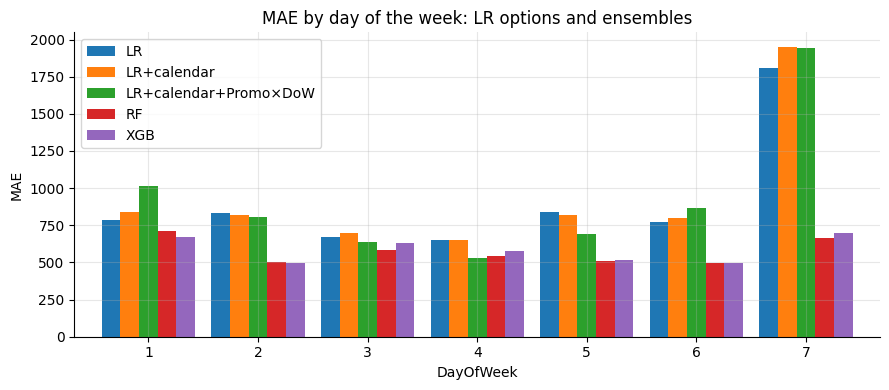

In [ ]:
dow = test_df["DayOfWeek"].astype(int).to_numpy()
t = pd.DataFrame({m: pd.Series(np.abs(y_te - preds[m])).groupby(dow).mean() for m in
                  ["LR", "LR+calendar", "LR+calendar+Promo×DoW", "RF", "XGB"]})
t.index.name = "DayOfWeek"; display(t.round(1)); t.round(2).to_csv(f"{TAB_DIR}/sensitivity_mae_by_dow.csv")

fig, ax = plt.subplots(figsize=(9, 4))
t.plot(kind="bar", ax=ax, width=.85); ax.set_ylabel("MAE"); ax.set_title("MAE by day of the week: LR options and ensembles")
ax.tick_params(axis="x", rotation=0); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_sensitivity_dow.png"), bbox_inches="tight", dpi=300); plt.show()